<a href="https://colab.research.google.com/github/machindie/Peramalan-Harga-Beras-di-Indonesia/blob/main/Peramalan%20Harga%20Beras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***Library***

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# **Input *Data***

In [ ]:
#Load data
df = pd.read_excel("databeras.xlsx")
pd.set_option('display.max_rows', None)
df

,Bulan,Harga
0,2018-01-01,12100
1,2018-02-01,12050
2,2018-03-01,11900
3,2018-04-01,11750
4,2018-05-01,11700
5,2018-06-01,11700
6,2018-07-01,11700
7,2018-08-01,11700
8,2018-09-01,11700
9,2018-10-01,11750


# **Proses Data**

## **Visualisasi *Data***

In [ ]:
import matplotlib.pyplot as plt

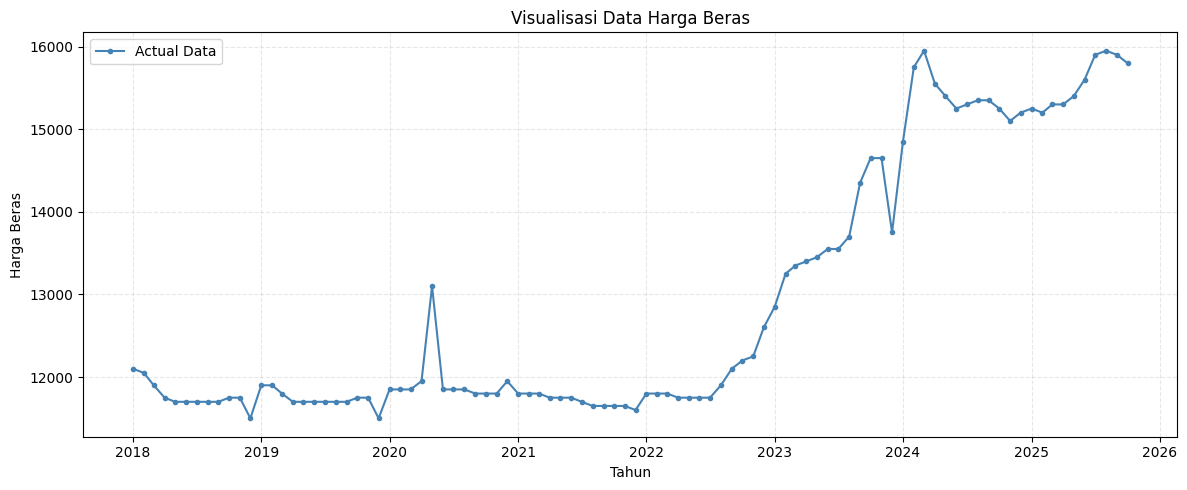

In [ ]:
#Visualisasi Data
plt.figure(figsize=(12, 5))

plt.plot(
    df['Bulan'],
    df['Harga'],
    color='steelblue',
    marker='o',
    markersize=3,
    linewidth=1.5,
    label='Actual Data'
)

plt.xlabel('Tahun')
plt.ylabel('Harga Beras')
plt.title('Visualisasi Data Harga Beras')

plt.grid(True, linestyle='--', alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

## **Analisis Deskriptif**

In [ ]:
# @title
stats_data = {
    'Statistik': ['Jumlah Data', 'Rata-rata', 'Nilai Maksimum', 'Nilai Tengah (Median)', 'Nilai Minimum', 'Standar Deviasi'],
    'Nilai': [
        int(df['Harga'].count()),
        int(round(df['Harga'].mean())),
        int(df['Harga'].max()),
        int(df['Harga'].median()),
        int(df['Harga'].min()),
        int(round(df['Harga'].std()))
    ]
}

df_stats = pd.DataFrame(stats_data)
df_stats

,Statistik,Nilai
0,Jumlah Data,94
1,Rata-rata,12915
2,Nilai Maksimum,15950
3,Nilai Tengah (Median),11875
4,Nilai Minimum,11500
5,Standar Deviasi,1569


## ***Splitting Data***

In [ ]:
data = df["Harga"].values
#Splitting data 80% training dan 20% testing
split_index = int(len(data) * 0.8)
train_data = data[:split_index]
test_data  = data[split_index:]
#Print data
print("Total data :", len(data))
print(data)
print("Train data :", len(train_data))
print(train_data)
print("Test data  :", len(test_data))
print(test_data)

Total data : 94
[12100 12050 11900 11750 11700 11700 11700 11700 11700 11750 11750 11500
 11900 11900 11800 11700 11700 11700 11700 11700 11700 11750 11750 11500
 11850 11850 11850 11950 13100 11850 11850 11850 11800 11800 11800 11950
 11800 11800 11800 11750 11750 11750 11700 11650 11650 11650 11650 11600
 11800 11800 11800 11750 11750 11750 11750 11900 12100 12200 12250 12600
 12850 13250 13350 13400 13450 13550 13550 13700 14350 14650 14650 13750
 14850 15750 15950 15550 15400 15250 15300 15350 15350 15250 15100 15200
 15250 15200 15300 15300 15400 15600 15900 15950 15900 15800]
Train data : 75
[12100 12050 11900 11750 11700 11700 11700 11700 11700 11750 11750 11500
 11900 11900 11800 11700 11700 11700 11700 11700 11700 11750 11750 11500
 11850 11850 11850 11950 13100 11850 11850 11850 11800 11800 11800 11950
 11800 11800 11800 11750 11750 11750 11700 11650 11650 11650 11650 11600
 11800 11800 11800 11750 11750 11750 11750 11900 12100 12200 12250 12600
 12850 13250 13350 13400 13450

## **Uji Stasioneritas (saran)**

In [ ]:
from statsmodels.tsa.stattools import adfuller
#Uji Stasioneritas Data
result = adfuller(df['Harga'])

print("ADF Statistic:", result[0])
print("p-value:", result[1])

#Taraf Signifikansi
alpha = 0.05

#Keputusan
if result[1] < alpha:
    print("Keputusan: Tolak H0 maka data stasioner")
else:
    print("Keputusan: Gagal tolak H0 maka data tidak stasioner")

ADF Statistic: 0.8441742378589379
p-value: 0.9923167751991518
Keputusan: Gagal tolak H0 maka data tidak stasioner


# -----------------------------------------------------------

# ***Particle Swarm Optimization***

### Parameter PSO

In [ ]:
#Parameter
np.random.seed(42)
num_particles = 40
max_iter = 400
c1, c2 = 1.5, 1.5
w = 0.3
xmin, xmax = 11500, 15950

### Fungsi FTS *Cheng*

In [ ]:
#Fungsi FTS Cheng
def ftscheng_mse_boundary(train_data, boundaries):

    boundaries = sorted(boundaries)

    #Bentuk interval
    bBawah = [xmin] + boundaries
    bAtas  = boundaries + [xmax]

    tengah = [(bBawah[i] + bAtas[i]) / 2 for i in range(len(bBawah))]

    kelas = ["A" + str(i+1) for i in range(len(bBawah))]

    #Fuzzifikasi
    fuzzy = []
    for x in train_data:
        for i in range(len(bBawah)):

            if i == len(bBawah) - 1:
                if bBawah[i] <= x <= bAtas[i]:
                    fuzzy.append(kelas[i])
                    break
            else:
                if bBawah[i] <= x < bAtas[i]:
                    fuzzy.append(kelas[i])
                    break

    #FLR
    flr = [(fuzzy[i-1], fuzzy[i]) for i in range(1, len(fuzzy))]

    #FLRG
    flrg = {}
    for a, b in flr:
        if a not in flrg:
            flrg[a] = []
        flrg[a].append(b)

    #Bobot
    bobot = {}
    for key, v in flrg.items():
        c = Counter(v)
        total = sum(c.values())
        bobot[key] = {kk: c[kk]/total for kk in c}

    #Defuzzifikasi
    defuzz = {}
    for key in bobot:
        val = 0
        for tujuan in bobot[key]:
            idx = kelas.index(tujuan)
            val += bobot[key][tujuan] * tengah[idx]
        defuzz[key] = val

    #Prediksi
    pred = [None]
    for i in range(1, len(fuzzy)):
        prev = fuzzy[i-1]

        if prev in defuzz:
            pred.append(defuzz[prev])
        else:
            idx = kelas.index(prev)
            pred.append(tengah[idx])

    actual = np.array(train_data[1:])
    forecast = np.array(pred[1:])

    mse = np.mean((actual - forecast)**2)
    return mse

### Inisialisasi Awal

In [ ]:
#Inisialisasi posisi awal secara random
def init_particles_pso(current_dim):
    population = np.array([np.sort(np.random.uniform(xmin, xmax, current_dim)) for _ in range(num_particles)])
    velocity = np.zeros((num_particles, current_dim))
    return population, velocity

### Hitung MSE Inisialisasi Awal

In [ ]:
#Hitung MSE
def calculate_mse_pso(population, train_data):
    return np.array([ftscheng_mse_boundary(train_data, sol) for sol in population])

### Tentukan Pbest dan Gbest Awal

In [ ]:
#Pbest dan Gbest
def get_gbest_pso(pbest, mse_pbest):
    idx = np.argmin(mse_pbest)
    return pbest[idx].copy(), mse_pbest[idx]

### Iterasi

In [ ]:
#Mencoba beberapa jumlah interval untuk optimasi panjang interval
rekap_hasil_pso = []

for k in range(8, 38):
    current_dim = k - 1

    print(f"\n(PSO) Jumlah Interval: {k}")

    ##Inisialisasi
    population_pso, velocity_pso = init_particles_pso(current_dim)

    #Fitness, Pbest dan Gbest
    mse_pso = calculate_mse_pso(population_pso, train_data)
    pbest_pso = population_pso.copy()
    mse_pbest_pso = mse_pso.copy()
    gbest_pso, mse_gbest_pso = get_gbest_pso(pbest_pso, mse_pbest_pso)

    #Print hasil inisialisasi awal
    if k == 32:
        print("\nInisialisasi")
        for i in range(num_particles):
            print(f"P{i+1}: {np.round(population_pso[i],0).astype(int)}")

        print("\nMSE Inisialisasi")
        for i in range(num_particles):
            print(f"P{i+1}: {mse_pso[i]:.3f}")

        print("\nPbest Inisialisasi")
        for i in range(num_particles):
            print(f"P{i+1}: {np.round(pbest_pso[i],0).astype(int)}")

        print("\nGbest Inisialisasi")
        print(np.round(gbest_pso,0).astype(int), "| MSE:", f"{mse_gbest_pso:.3f}")

    prev_mse = mse_gbest_pso
    stagnan = 0

    for it in range(1, max_iter + 1):   #Dimulai dari iterasi 1
        for i in range(num_particles):
            for j in range(current_dim):
                r1, r2 = np.random.rand(), np.random.rand()
                velocity_pso[i, j] = (w * velocity_pso[i, j] +
                                      c1 * r1 * (pbest_pso[i, j] - population_pso[i, j]) +
                                      c2 * r2 * (gbest_pso[j] - population_pso[i, j]))

        population_pso = np.sort(np.clip(population_pso + velocity_pso, xmin, xmax), axis=1)
        mse_pso = calculate_mse_pso(population_pso, train_data)

        for i in range(len(population_pso)):
            if mse_pso[i] < mse_pbest_pso[i]:
                pbest_pso[i] = population_pso[i].copy()
                mse_pbest_pso[i] = mse_pso[i]

        gbest_pso, mse_gbest_pso = get_gbest_pso(pbest_pso, mse_pbest_pso)

        #Tampilkan hasil iterasi 1
        if k == 32 and it == 1:
            print("\nIterasi 1")

            print("\nUpdate Velocity")
            for i in range(num_particles):
                print(f"P{i+1}: {np.round(velocity_pso[i],2)}")

            print("\nUpdate Posisi")
            for i in range(num_particles):
                print(f"P{i+1}: {np.round(population_pso[i],0).astype(int)}")

            print("\nPbest")
            for i in range(num_particles):
                print(f"P{i+1}: {np.round(pbest_pso[i],0).astype(int)}")

            print("\nGbest")
            print(np.round(gbest_pso,0).astype(int), "| MSE:", f"{mse_gbest_pso:.3f}")

        if abs(prev_mse - mse_gbest_pso) < 1e-3:
            stagnan += 1
            if stagnan >= 10:
                break
        else:
            stagnan = 0

        prev_mse = mse_gbest_pso

    #Iterasi
    final_it = it

    #Simpan Hasil
    rekap_hasil_pso.append({
        'interval': k,
        'mse': mse_gbest_pso,
        'boundary': gbest_pso.copy(),
        'iterasi': final_it
    })

    print(f"(PSO) Interval {k} | MSE: {mse_gbest_pso:.3f} | Iterasi: {final_it}")


(PSO) Jumlah Interval: 8
(PSO) Interval 8 | MSE: 46573.454 | Iterasi: 98

(PSO) Jumlah Interval: 9
(PSO) Interval 9 | MSE: 46647.769 | Iterasi: 166

(PSO) Jumlah Interval: 10
(PSO) Interval 10 | MSE: 32650.607 | Iterasi: 224

(PSO) Jumlah Interval: 11
(PSO) Interval 11 | MSE: 31447.256 | Iterasi: 387

(PSO) Jumlah Interval: 12
(PSO) Interval 12 | MSE: 31004.077 | Iterasi: 327

(PSO) Jumlah Interval: 13
(PSO) Interval 13 | MSE: 33406.206 | Iterasi: 99

(PSO) Jumlah Interval: 14
(PSO) Interval 14 | MSE: 29004.122 | Iterasi: 228

(PSO) Jumlah Interval: 15
(PSO) Interval 15 | MSE: 30487.316 | Iterasi: 151

(PSO) Jumlah Interval: 16
(PSO) Interval 16 | MSE: 27508.588 | Iterasi: 132

(PSO) Jumlah Interval: 17
(PSO) Interval 17 | MSE: 28227.044 | Iterasi: 218

(PSO) Jumlah Interval: 18
(PSO) Interval 18 | MSE: 28548.966 | Iterasi: 173

(PSO) Jumlah Interval: 19
(PSO) Interval 19 | MSE: 27538.850 | Iterasi: 289

(PSO) Jumlah Interval: 20
(PSO) Interval 20 | MSE: 23934.641 | Iterasi: 207

(PSO

In [ ]:
#Mencoba beberapa jumlah interval untuk optimasi panjang interval
rekap_hasil_pso = []

for k in range(8, 38):
    current_dim = k - 1

    print(f"\n(PSO) Jumlah Interval: {k}")

    ##Inisialisasi
    population_pso, velocity_pso = init_particles_pso(current_dim)

    #Fitness, Pbest dan Gbest
    mse_pso = calculate_mse_pso(population_pso, train_data)
    pbest_pso = population_pso.copy()
    mse_pbest_pso = mse_pso.copy()
    gbest_pso, mse_gbest_pso = get_gbest_pso(pbest_pso, mse_pbest_pso)

    #Print hasil inisialisasi awal
    if k == 32:
        print("\nInisialisasi")
        for i in range(num_particles):
            print(f"P{i+1}: {np.round(population_pso[i],0).astype(int)}")

        print("\nMSE Inisialisasi")
        for i in range(num_particles):
            print(f"P{i+1}: {mse_pso[i]:.3f}")

        print("\nPbest Inisialisasi")
        for i in range(num_particles):
            print(f"P{i+1}: {np.round(pbest_pso[i],0).astype(int)}")

        print("\nGbest Inisialisasi")
        print(np.round(gbest_pso,0).astype(int), "| MSE:", f"{mse_gbest_pso:.3f}")

    prev_mse = mse_gbest_pso
    stagnan = 0

    for it in range(1, max_iter + 1):   #Dimulai dari iterasi 1
        for i in range(num_particles):
            for j in range(current_dim):
                r1, r2 = np.random.rand(), np.random.rand()
                velocity_pso[i, j] = (w * velocity_pso[i, j] +
                                      c1 * r1 * (pbest_pso[i, j] - population_pso[i, j]) +
                                      c2 * r2 * (gbest_pso[j] - population_pso[i, j]))

        population_pso = np.sort(np.clip(population_pso + velocity_pso, xmin, xmax), axis=1)
        mse_pso = calculate_mse_pso(population_pso, train_data)

        for i in range(len(population_pso)):
            if mse_pso[i] < mse_pbest_pso[i]:
                pbest_pso[i] = population_pso[i].copy()
                mse_pbest_pso[i] = mse_pso[i]

        gbest_pso, mse_gbest_pso = get_gbest_pso(pbest_pso, mse_pbest_pso)

        #Tampilkan hasil iterasi 1
        if k == 32 and it == 1:
            print("\nIterasi 1")

            print("\nUpdate Velocity")
            for i in range(num_particles):
                print(f"P{i+1}: {np.round(velocity_pso[i],2)}")

            print("\nUpdate Posisi")
            for i in range(num_particles):
                print(f"P{i+1}: {np.round(population_pso[i],0).astype(int)}")

            print("\nPbest")
            for i in range(num_particles):
                print(f"P{i+1}: {np.round(pbest_pso[i],0).astype(int)}")

            print("\nGbest")
            print(np.round(gbest_pso,0).astype(int), "| MSE:", f"{mse_gbest_pso:.3f}")

        if abs(prev_mse - mse_gbest_pso) < 1e-3:
            stagnan += 1
            if stagnan >= 10:
                break
        else:
            stagnan = 0

        prev_mse = mse_gbest_pso

    #Iterasi
    final_it = it

    #Simpan Hasil
    rekap_hasil_pso.append({
        'interval': k,
        'mse': mse_gbest_pso,
        'boundary': gbest_pso.copy(),
        'iterasi': final_it
    })

    print(f"(PSO) Interval {k} | MSE: {mse_gbest_pso:.3f} | Iterasi: {final_it}")


(PSO) Jumlah Interval: 8
(PSO) Interval 8 | MSE: 46573.454 | Iterasi: 98

(PSO) Jumlah Interval: 9
(PSO) Interval 9 | MSE: 46647.769 | Iterasi: 166

(PSO) Jumlah Interval: 10
(PSO) Interval 10 | MSE: 32650.607 | Iterasi: 224

(PSO) Jumlah Interval: 11
(PSO) Interval 11 | MSE: 31447.256 | Iterasi: 387

(PSO) Jumlah Interval: 12
(PSO) Interval 12 | MSE: 31004.077 | Iterasi: 327

(PSO) Jumlah Interval: 13
(PSO) Interval 13 | MSE: 33406.206 | Iterasi: 99

(PSO) Jumlah Interval: 14
(PSO) Interval 14 | MSE: 29004.122 | Iterasi: 228

(PSO) Jumlah Interval: 15
(PSO) Interval 15 | MSE: 30487.316 | Iterasi: 151

(PSO) Jumlah Interval: 16
(PSO) Interval 16 | MSE: 27508.588 | Iterasi: 132

(PSO) Jumlah Interval: 17
(PSO) Interval 17 | MSE: 28227.044 | Iterasi: 218

(PSO) Jumlah Interval: 18
(PSO) Interval 18 | MSE: 28548.966 | Iterasi: 173

(PSO) Jumlah Interval: 19
(PSO) Interval 19 | MSE: 27538.850 | Iterasi: 289

(PSO) Jumlah Interval: 20
(PSO) Interval 20 | MSE: 23934.641 | Iterasi: 207

(PSO

### Tampilkan Hasil

In [ ]:
#Tampilkan hasil penerapan semua interval
print("\nTABEL HASIL (8-37):")
print(f"{'Interval':<10} | {'MSE Terbaik':<15}")
print("-" * 30)

for item in rekap_hasil_pso:
    print(f"{item['interval']:<10} | {item['mse']:<15.3f}")

final_best = min(rekap_hasil_pso, key=lambda x: x['mse'])
print(f"\nKesimpulan: Jumlah Interval terbaik adalah {final_best['interval']} dengan MSE {final_best['mse']:.3f}")


TABEL HASIL (8-37):
Interval   | MSE Terbaik    
------------------------------
8          | 46573.454      
9          | 46647.769      
10         | 32650.607      
11         | 31447.256      
12         | 31004.077      
13         | 33406.206      
14         | 29004.122      
15         | 30487.316      
16         | 27508.588      
17         | 28227.044      
18         | 28548.966      
19         | 27538.850      
20         | 23934.641      
21         | 24317.162      
22         | 25479.480      
23         | 22651.717      
24         | 25849.518      
25         | 22564.032      
26         | 24092.293      
27         | 22966.874      
28         | 22451.247      
29         | 21650.636      
30         | 22058.668      
31         | 22027.950      
32         | 21252.960      
33         | 22620.350      
34         | 21366.236      
35         | 21545.241      
36         | 22519.341      
37         | 21478.923      

Kesimpulan: Jumlah Interval terbaik adalah 32 de

In [ ]:
#Tampilkan hasil penerapan semua interval
print("\nTABEL HASIL (8-37):")
print(f"{'Interval':<10} | {'MSE Terbaik':<15}")
print("-" * 30)

for item in rekap_hasil_pso:
    print(f"{item['interval']:<10} | {item['mse']:<15.3f}")

final_best = min(rekap_hasil_pso, key=lambda x: x['mse'])
print(f"\nKesimpulan: Jumlah Interval terbaik adalah {final_best['interval']} dengan MSE {final_best['mse']:.3f}")


TABEL HASIL (8-37):
Interval   | MSE Terbaik    
------------------------------
8          | 46573.454      
9          | 46647.769      
10         | 32650.607      
11         | 31447.256      
12         | 31004.077      
13         | 33406.206      
14         | 29004.122      
15         | 30487.316      
16         | 27508.588      
17         | 28227.044      
18         | 28548.966      
19         | 27538.850      
20         | 23934.641      
21         | 24317.162      
22         | 25479.480      
23         | 22651.717      
24         | 25849.518      
25         | 22564.032      
26         | 24092.293      
27         | 22966.874      
28         | 22451.247      
29         | 21650.636      
30         | 22058.668      
31         | 22027.950      
32         | 21252.960      
33         | 22620.350      
34         | 21366.236      
35         | 21545.241      
36         | 22519.341      
37         | 21478.923      

Kesimpulan: Jumlah Interval terbaik adalah 32 de

In [ ]:
#Tampilkan hasil interval optimal
hasiloptpso = min(rekap_hasil_pso, key=lambda x: x['mse'])

print(f"{'='*40}")
print(f"HASIL TERBAIK:")
print(f"{'='*40}")
print(f"Jumlah Interval Optimal       : {hasiloptpso['interval']}")
print(f"Nilai MSE Paling Rendah      : {hasiloptpso['mse']:.6f}")
print(f"Iterasi Berhenti             : {hasiloptpso['iterasi']}")
print(f"{'-'*40}")
print(f"Batas Interval Optimal (Hasil PSO):")
print(np.round(hasiloptpso['boundary'], 0).astype(int))
print(f"{'='*40}")

HASIL TERBAIK:
Jumlah Interval Optimal       : 32
Nilai MSE Paling Rendah      : 21252.960046
Iterasi Berhenti             : 299
----------------------------------------
Batas Interval Optimal (Hasil PSO):
[11638 11693 11702 11774 11829 11869 11906 12022 12050 12200 12519 12685
 12723 12998 13149 13221 13292 13413 13539 13606 13700 14071 14517 14768
 14905 15129 15395 15490 15510 15716 15895]


In [ ]:
#Tampilkan hasil interval optimal
hasiloptpso = min(rekap_hasil_pso, key=lambda x: x['mse'])

print(f"{'='*40}")
print(f"HASIL TERBAIK:")
print(f"{'='*40}")
print(f"Jumlah Interval Optimal       : {hasiloptpso['interval']}")
print(f"Nilai MSE Paling Rendah      : {hasiloptpso['mse']:.6f}")
print(f"Iterasi Berhenti             : {hasiloptpso['iterasi']}")
print(f"{'-'*40}")
print(f"Batas Interval Optimal (Hasil PSO):")
print(np.round(hasiloptpso['boundary'], 0).astype(int))
print(f"{'='*40}")

HASIL TERBAIK:
Jumlah Interval Optimal       : 32
Nilai MSE Paling Rendah      : 21252.960046
Iterasi Berhenti             : 299
----------------------------------------
Batas Interval Optimal (Hasil PSO):
[11638 11693 11702 11774 11829 11869 11906 12022 12050 12200 12519 12685
 12723 12998 13149 13221 13292 13413 13539 13606 13700 14071 14517 14768
 14905 15129 15395 15490 15510 15716 15895]


### Grafik

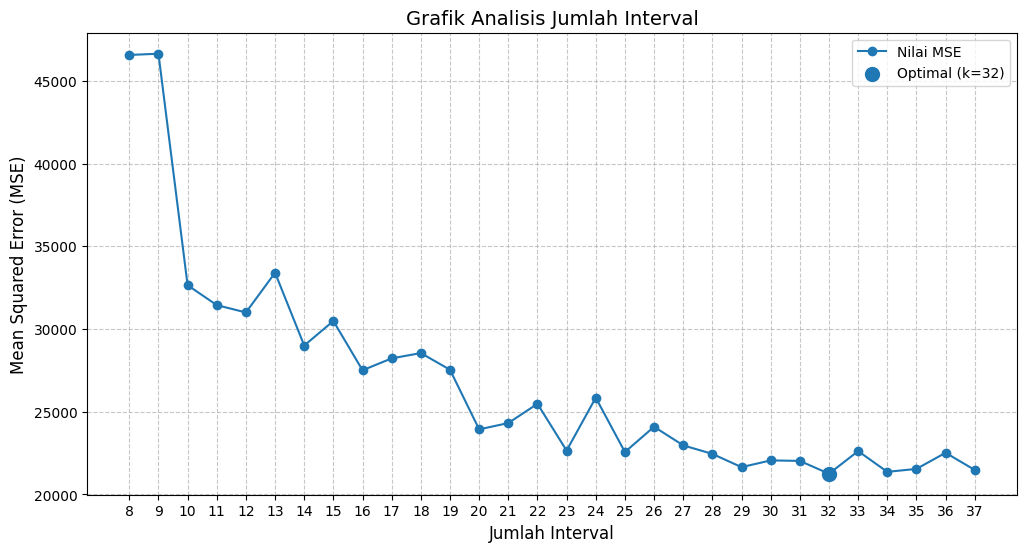

In [ ]:
#Ambil hasil interval optimal
intervals = [item['interval'] for item in rekap_hasil_pso]
mse_values = [item['mse'] for item in rekap_hasil_pso]

#Titik optimal
min_mse = min(mse_values)
best_k = intervals[mse_values.index(min_mse)]

#Plot
plt.figure(figsize=(12, 6))
plt.plot(intervals, mse_values, marker='o', linestyle='-', label='Nilai MSE')

#Tandai titik optimal
plt.scatter(best_k, min_mse, s=100, label=f'Optimal (k={best_k})', zorder=5)

plt.title('Grafik Analisis Jumlah Interval', fontsize=14)
plt.xlabel('Jumlah Interval', fontsize=12)
plt.ylabel('Mean Squared Error (MSE)', fontsize=12)
plt.xticks(intervals)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

plt.show()

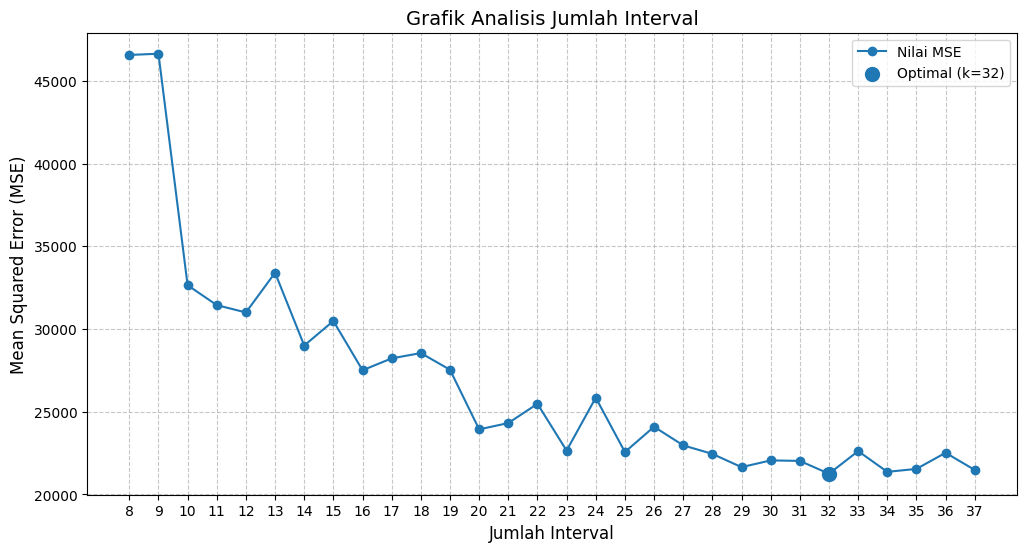

In [ ]:
#Ambil hasil interval optimal
intervals = [item['interval'] for item in rekap_hasil_pso]
mse_values = [item['mse'] for item in rekap_hasil_pso]

#Titik optimal
min_mse = min(mse_values)
best_k = intervals[mse_values.index(min_mse)]

#Plot
plt.figure(figsize=(12, 6))
plt.plot(intervals, mse_values, marker='o', linestyle='-', label='Nilai MSE')

#Tandai titik optimal
plt.scatter(best_k, min_mse, s=100, label=f'Optimal (k={best_k})', zorder=5)

plt.title('Grafik Analisis Jumlah Interval', fontsize=14)
plt.xlabel('Jumlah Interval', fontsize=12)
plt.ylabel('Mean Squared Error (MSE)', fontsize=12)
plt.xticks(intervals)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

plt.show()

# ***Fuzzy Time Series Cheng* - PSO**

### Interval Optimal dan Nilai Tengah Hasil PSO

In [ ]:
#Interval Optimal Hasil PSO
boundaries_pso = sorted(hasiloptpso['boundary'])

bBawah_pso = [xmin] + list(boundaries_pso)
bAtas_pso  = list(boundaries_pso) + [xmax]

#Batas Bawah dan Batas Atas
bBawah_pso = [int(round(x)) for x in bBawah_pso]
bAtas_pso  = [int(round(x)) for x in bAtas_pso]

#Nilai tengah
tengah_pso = [int(round((bBawah_pso[i] + bAtas_pso[i]) / 2)) for i in range(len(bBawah_pso))]

#Kelas
K_pso = len(bBawah_pso)
kelas_pso = [f"A{i+1}" for i in range(K_pso)]

#Tampilkan
print("\nInterval dan Nilai Tengah:\n")
for i in range(K_pso):
    print(f"{kelas_pso[i]:2s} → {bBawah_pso[i]} - {bAtas_pso[i]} | Midpoint: {tengah_pso[i]}")


Interval dan Nilai Tengah:

A1 → 11500 - 11638 | Midpoint: 11569
A2 → 11638 - 11693 | Midpoint: 11666
A3 → 11693 - 11702 | Midpoint: 11698
A4 → 11702 - 11774 | Midpoint: 11738
A5 → 11774 - 11829 | Midpoint: 11802
A6 → 11829 - 11869 | Midpoint: 11849
A7 → 11869 - 11906 | Midpoint: 11888
A8 → 11906 - 12022 | Midpoint: 11964
A9 → 12022 - 12050 | Midpoint: 12036
A10 → 12050 - 12200 | Midpoint: 12125
A11 → 12200 - 12519 | Midpoint: 12360
A12 → 12519 - 12685 | Midpoint: 12602
A13 → 12685 - 12723 | Midpoint: 12704
A14 → 12723 - 12998 | Midpoint: 12860
A15 → 12998 - 13149 | Midpoint: 13074
A16 → 13149 - 13221 | Midpoint: 13185
A17 → 13221 - 13292 | Midpoint: 13256
A18 → 13292 - 13413 | Midpoint: 13352
A19 → 13413 - 13539 | Midpoint: 13476
A20 → 13539 - 13606 | Midpoint: 13572
A21 → 13606 - 13700 | Midpoint: 13653
A22 → 13700 - 14071 | Midpoint: 13886
A23 → 14071 - 14517 | Midpoint: 14294
A24 → 14517 - 14768 | Midpoint: 14642
A25 → 14768 - 14905 | Midpoint: 14836
A26 → 14905 - 15129 | Midpoint

In [ ]:
#Interval Optimal Hasil PSO
boundaries_pso = sorted(hasiloptpso['boundary'])

bBawah_pso = [xmin] + list(boundaries_pso)
bAtas_pso  = list(boundaries_pso) + [xmax]

#Batas Bawah dan Batas Atas
bBawah_pso = [int(round(x)) for x in bBawah_pso]
bAtas_pso  = [int(round(x)) for x in bAtas_pso]

#Nilai tengah
tengah_pso = [int(round((bBawah_pso[i] + bAtas_pso[i]) / 2)) for i in range(len(bBawah_pso))]

#Kelas
K_pso = len(bBawah_pso)
kelas_pso = [f"A{i+1}" for i in range(K_pso)]

#Tampilkan
print("\nInterval dan Nilai Tengah:\n")
for i in range(K_pso):
    print(f"{kelas_pso[i]:2s} → {bBawah_pso[i]} - {bAtas_pso[i]} | Midpoint: {tengah_pso[i]}")


Interval dan Nilai Tengah:

A1 → 11500 - 11638 | Midpoint: 11569
A2 → 11638 - 11693 | Midpoint: 11666
A3 → 11693 - 11702 | Midpoint: 11698
A4 → 11702 - 11774 | Midpoint: 11738
A5 → 11774 - 11829 | Midpoint: 11802
A6 → 11829 - 11869 | Midpoint: 11849
A7 → 11869 - 11906 | Midpoint: 11888
A8 → 11906 - 12022 | Midpoint: 11964
A9 → 12022 - 12050 | Midpoint: 12036
A10 → 12050 - 12200 | Midpoint: 12125
A11 → 12200 - 12519 | Midpoint: 12360
A12 → 12519 - 12685 | Midpoint: 12602
A13 → 12685 - 12723 | Midpoint: 12704
A14 → 12723 - 12998 | Midpoint: 12860
A15 → 12998 - 13149 | Midpoint: 13074
A16 → 13149 - 13221 | Midpoint: 13185
A17 → 13221 - 13292 | Midpoint: 13256
A18 → 13292 - 13413 | Midpoint: 13352
A19 → 13413 - 13539 | Midpoint: 13476
A20 → 13539 - 13606 | Midpoint: 13572
A21 → 13606 - 13700 | Midpoint: 13653
A22 → 13700 - 14071 | Midpoint: 13886
A23 → 14071 - 14517 | Midpoint: 14294
A24 → 14517 - 14768 | Midpoint: 14642
A25 → 14768 - 14905 | Midpoint: 14836
A26 → 14905 - 15129 | Midpoint

### Fuzzifikasi *Training*

In [ ]:
#Fuzzifikasi Training
print("\nFuzzifikasi Training\n")

fuzzy_train_pso = []

for x in train_data:
    for i in range(K_pso):

        if i == K_pso - 1:
            if bBawah_pso[i] <= x <= bAtas_pso[i]:
                fuzzy_train_pso.append(kelas_pso[i])
                break
        else:
            if bBawah_pso[i] <= x < bAtas_pso[i]:
                fuzzy_train_pso.append(kelas_pso[i])
                break

#Tampilkan Hasil
print("Hasil Fuzzifikasi Training:", fuzzy_train_pso)


Fuzzifikasi Training

Hasil Fuzzifikasi Training: ['A10', 'A10', 'A7', 'A4', 'A3', 'A3', 'A3', 'A3', 'A3', 'A4', 'A4', 'A1', 'A7', 'A7', 'A5', 'A3', 'A3', 'A3', 'A3', 'A3', 'A3', 'A4', 'A4', 'A1', 'A6', 'A6', 'A6', 'A8', 'A15', 'A6', 'A6', 'A6', 'A5', 'A5', 'A5', 'A8', 'A5', 'A5', 'A5', 'A4', 'A4', 'A4', 'A3', 'A2', 'A2', 'A2', 'A2', 'A1', 'A5', 'A5', 'A5', 'A4', 'A4', 'A4', 'A4', 'A7', 'A10', 'A11', 'A11', 'A12', 'A14', 'A17', 'A18', 'A18', 'A19', 'A20', 'A20', 'A22', 'A23', 'A24', 'A24', 'A22', 'A25', 'A31', 'A32']


In [ ]:
#Fuzzifikasi Training
print("\nFuzzifikasi Training\n")

fuzzy_train_pso = []

for x in train_data:
    for i in range(K_pso):

        if i == K_pso - 1:
            if bBawah_pso[i] <= x <= bAtas_pso[i]:
                fuzzy_train_pso.append(kelas_pso[i])
                break
        else:
            if bBawah_pso[i] <= x < bAtas_pso[i]:
                fuzzy_train_pso.append(kelas_pso[i])
                break

#Tampilkan Hasil
print("Hasil Fuzzifikasi Training:", fuzzy_train_pso)


Fuzzifikasi Training

Hasil Fuzzifikasi Training: ['A10', 'A10', 'A7', 'A4', 'A3', 'A3', 'A3', 'A3', 'A3', 'A4', 'A4', 'A1', 'A7', 'A7', 'A5', 'A3', 'A3', 'A3', 'A3', 'A3', 'A3', 'A4', 'A4', 'A1', 'A6', 'A6', 'A6', 'A8', 'A15', 'A6', 'A6', 'A6', 'A5', 'A5', 'A5', 'A8', 'A5', 'A5', 'A5', 'A4', 'A4', 'A4', 'A3', 'A2', 'A2', 'A2', 'A2', 'A1', 'A5', 'A5', 'A5', 'A4', 'A4', 'A4', 'A4', 'A7', 'A10', 'A11', 'A11', 'A12', 'A14', 'A17', 'A18', 'A18', 'A19', 'A20', 'A20', 'A22', 'A23', 'A24', 'A24', 'A22', 'A25', 'A31', 'A32']


### *FLR*

In [ ]:
#FLR
print("\nFLR\n")

flr_pso = [(fuzzy_train_pso[i-1], fuzzy_train_pso[i]) for i in range(1, len(fuzzy_train_pso))]

#Tampilkan Hasil
print("Hasil FLR:", flr_pso)


FLR

Hasil FLR: [('A10', 'A10'), ('A10', 'A7'), ('A7', 'A4'), ('A4', 'A3'), ('A3', 'A3'), ('A3', 'A3'), ('A3', 'A3'), ('A3', 'A3'), ('A3', 'A4'), ('A4', 'A4'), ('A4', 'A1'), ('A1', 'A7'), ('A7', 'A7'), ('A7', 'A5'), ('A5', 'A3'), ('A3', 'A3'), ('A3', 'A3'), ('A3', 'A3'), ('A3', 'A3'), ('A3', 'A3'), ('A3', 'A4'), ('A4', 'A4'), ('A4', 'A1'), ('A1', 'A6'), ('A6', 'A6'), ('A6', 'A6'), ('A6', 'A8'), ('A8', 'A15'), ('A15', 'A6'), ('A6', 'A6'), ('A6', 'A6'), ('A6', 'A5'), ('A5', 'A5'), ('A5', 'A5'), ('A5', 'A8'), ('A8', 'A5'), ('A5', 'A5'), ('A5', 'A5'), ('A5', 'A4'), ('A4', 'A4'), ('A4', 'A4'), ('A4', 'A3'), ('A3', 'A2'), ('A2', 'A2'), ('A2', 'A2'), ('A2', 'A2'), ('A2', 'A1'), ('A1', 'A5'), ('A5', 'A5'), ('A5', 'A5'), ('A5', 'A4'), ('A4', 'A4'), ('A4', 'A4'), ('A4', 'A4'), ('A4', 'A7'), ('A7', 'A10'), ('A10', 'A11'), ('A11', 'A11'), ('A11', 'A12'), ('A12', 'A14'), ('A14', 'A17'), ('A17', 'A18'), ('A18', 'A18'), ('A18', 'A19'), ('A19', 'A20'), ('A20', 'A20'), ('A20', 'A22'), ('A22', 'A23'), 

In [ ]:
#FLR
print("\nFLR\n")

flr_pso = [(fuzzy_train_pso[i-1], fuzzy_train_pso[i]) for i in range(1, len(fuzzy_train_pso))]

#Tampilkan Hasil
print("Hasil FLR:", flr_pso)


FLR

Hasil FLR: [('A10', 'A10'), ('A10', 'A7'), ('A7', 'A4'), ('A4', 'A3'), ('A3', 'A3'), ('A3', 'A3'), ('A3', 'A3'), ('A3', 'A3'), ('A3', 'A4'), ('A4', 'A4'), ('A4', 'A1'), ('A1', 'A7'), ('A7', 'A7'), ('A7', 'A5'), ('A5', 'A3'), ('A3', 'A3'), ('A3', 'A3'), ('A3', 'A3'), ('A3', 'A3'), ('A3', 'A3'), ('A3', 'A4'), ('A4', 'A4'), ('A4', 'A1'), ('A1', 'A6'), ('A6', 'A6'), ('A6', 'A6'), ('A6', 'A8'), ('A8', 'A15'), ('A15', 'A6'), ('A6', 'A6'), ('A6', 'A6'), ('A6', 'A5'), ('A5', 'A5'), ('A5', 'A5'), ('A5', 'A8'), ('A8', 'A5'), ('A5', 'A5'), ('A5', 'A5'), ('A5', 'A4'), ('A4', 'A4'), ('A4', 'A4'), ('A4', 'A3'), ('A3', 'A2'), ('A2', 'A2'), ('A2', 'A2'), ('A2', 'A2'), ('A2', 'A1'), ('A1', 'A5'), ('A5', 'A5'), ('A5', 'A5'), ('A5', 'A4'), ('A4', 'A4'), ('A4', 'A4'), ('A4', 'A4'), ('A4', 'A7'), ('A7', 'A10'), ('A10', 'A11'), ('A11', 'A11'), ('A11', 'A12'), ('A12', 'A14'), ('A14', 'A17'), ('A17', 'A18'), ('A18', 'A18'), ('A18', 'A19'), ('A19', 'A20'), ('A20', 'A20'), ('A20', 'A22'), ('A22', 'A23'), 

### *FLRG*

In [ ]:
#FLRG
print("\nFLRG\n")

flrg_pso = {}
for a, b in flr_pso:
    if a not in flrg_pso:
        flrg_pso[a] = []
    flrg_pso[a].append(b)

#Tampilkan Hasil
for key in flrg_pso:
    print(f"{key} → {flrg_pso[key]}")


FLRG

A10 → ['A10', 'A7', 'A11']
A7 → ['A4', 'A7', 'A5', 'A10']
A4 → ['A3', 'A4', 'A1', 'A4', 'A1', 'A4', 'A4', 'A3', 'A4', 'A4', 'A4', 'A7']
A3 → ['A3', 'A3', 'A3', 'A3', 'A4', 'A3', 'A3', 'A3', 'A3', 'A3', 'A4', 'A2']
A1 → ['A7', 'A6', 'A5']
A5 → ['A3', 'A5', 'A5', 'A8', 'A5', 'A5', 'A4', 'A5', 'A5', 'A4']
A6 → ['A6', 'A6', 'A8', 'A6', 'A6', 'A5']
A8 → ['A15', 'A5']
A15 → ['A6']
A2 → ['A2', 'A2', 'A2', 'A1']
A11 → ['A11', 'A12']
A12 → ['A14']
A14 → ['A17']
A17 → ['A18']
A18 → ['A18', 'A19']
A19 → ['A20']
A20 → ['A20', 'A22']
A22 → ['A23', 'A25']
A23 → ['A24']
A24 → ['A24', 'A22']
A25 → ['A31']
A31 → ['A32']


In [ ]:
#FLRG
print("\nFLRG\n")

flrg_pso = {}
for a, b in flr_pso:
    if a not in flrg_pso:
        flrg_pso[a] = []
    flrg_pso[a].append(b)

#Tampilkan Hasil
for key in flrg_pso:
    print(f"{key} → {flrg_pso[key]}")


FLRG

A10 → ['A10', 'A7', 'A11']
A7 → ['A4', 'A7', 'A5', 'A10']
A4 → ['A3', 'A4', 'A1', 'A4', 'A1', 'A4', 'A4', 'A3', 'A4', 'A4', 'A4', 'A7']
A3 → ['A3', 'A3', 'A3', 'A3', 'A4', 'A3', 'A3', 'A3', 'A3', 'A3', 'A4', 'A2']
A1 → ['A7', 'A6', 'A5']
A5 → ['A3', 'A5', 'A5', 'A8', 'A5', 'A5', 'A4', 'A5', 'A5', 'A4']
A6 → ['A6', 'A6', 'A8', 'A6', 'A6', 'A5']
A8 → ['A15', 'A5']
A15 → ['A6']
A2 → ['A2', 'A2', 'A2', 'A1']
A11 → ['A11', 'A12']
A12 → ['A14']
A14 → ['A17']
A17 → ['A18']
A18 → ['A18', 'A19']
A19 → ['A20']
A20 → ['A20', 'A22']
A22 → ['A23', 'A25']
A23 → ['A24']
A24 → ['A24', 'A22']
A25 → ['A31']
A31 → ['A32']


### Pembobotan

In [ ]:
#Pembobotan PSO
print("\nPembobotan PSO\n")

bobot_pso = {}
for key, v in flrg_pso.items():
    c = Counter(v)
    total = sum(c.values())
    bobot_pso[key] = {kk: round(c[kk]/total, 3) for kk in c}

#Tampilkan Hasil
for key in bobot_pso:
    print(f"{key} → {bobot_pso[key]}")


Pembobotan PSO

A10 → {'A10': 0.333, 'A7': 0.333, 'A11': 0.333}
A7 → {'A4': 0.25, 'A7': 0.25, 'A5': 0.25, 'A10': 0.25}
A4 → {'A3': 0.167, 'A4': 0.583, 'A1': 0.167, 'A7': 0.083}
A3 → {'A3': 0.75, 'A4': 0.167, 'A2': 0.083}
A1 → {'A7': 0.333, 'A6': 0.333, 'A5': 0.333}
A5 → {'A3': 0.1, 'A5': 0.6, 'A8': 0.1, 'A4': 0.2}
A6 → {'A6': 0.667, 'A8': 0.167, 'A5': 0.167}
A8 → {'A15': 0.5, 'A5': 0.5}
A15 → {'A6': 1.0}
A2 → {'A2': 0.75, 'A1': 0.25}
A11 → {'A11': 0.5, 'A12': 0.5}
A12 → {'A14': 1.0}
A14 → {'A17': 1.0}
A17 → {'A18': 1.0}
A18 → {'A18': 0.5, 'A19': 0.5}
A19 → {'A20': 1.0}
A20 → {'A20': 0.5, 'A22': 0.5}
A22 → {'A23': 0.5, 'A25': 0.5}
A23 → {'A24': 1.0}
A24 → {'A24': 0.5, 'A22': 0.5}
A25 → {'A31': 1.0}
A31 → {'A32': 1.0}


In [ ]:
#Pembobotan PSO
print("\nPembobotan PSO\n")

bobot_pso = {}
for key, v in flrg_pso.items():
    c = Counter(v)
    total = sum(c.values())
    bobot_pso[key] = {kk: round(c[kk]/total, 3) for kk in c}

#Tampilkan Hasil
for key in bobot_pso:
    print(f"{key} → {bobot_pso[key]}")


Pembobotan PSO

A10 → {'A10': 0.333, 'A7': 0.333, 'A11': 0.333}
A7 → {'A4': 0.25, 'A7': 0.25, 'A5': 0.25, 'A10': 0.25}
A4 → {'A3': 0.167, 'A4': 0.583, 'A1': 0.167, 'A7': 0.083}
A3 → {'A3': 0.75, 'A4': 0.167, 'A2': 0.083}
A1 → {'A7': 0.333, 'A6': 0.333, 'A5': 0.333}
A5 → {'A3': 0.1, 'A5': 0.6, 'A8': 0.1, 'A4': 0.2}
A6 → {'A6': 0.667, 'A8': 0.167, 'A5': 0.167}
A8 → {'A15': 0.5, 'A5': 0.5}
A15 → {'A6': 1.0}
A2 → {'A2': 0.75, 'A1': 0.25}
A11 → {'A11': 0.5, 'A12': 0.5}
A12 → {'A14': 1.0}
A14 → {'A17': 1.0}
A17 → {'A18': 1.0}
A18 → {'A18': 0.5, 'A19': 0.5}
A19 → {'A20': 1.0}
A20 → {'A20': 0.5, 'A22': 0.5}
A22 → {'A23': 0.5, 'A25': 0.5}
A23 → {'A24': 1.0}
A24 → {'A24': 0.5, 'A22': 0.5}
A25 → {'A31': 1.0}
A31 → {'A32': 1.0}


### Defuzzifikasi

In [ ]:
# Defuzzifikasi PSO
print("\nDefuzzifikasi PSO\n")

defuzz_pso = {}
for key in bobot_pso:
    val = 0
    for tujuan in bobot_pso[key]:
        idx = kelas_pso.index(tujuan)
        val += bobot_pso[key][tujuan] * tengah_pso[idx]

    defuzz_pso[key] = round(val, 3)

# Tampilkan Hasil dengan format sejajar
for key in defuzz_pso:
    print(f"{key} → {defuzz_pso[key]:.3f}")


Defuzzifikasi PSO

A10 → 12112.209
A7 → 11888.250
A4 → 11715.547
A3 → 11702.024
A1 → 11834.487
A5 → 11795.000
A6 → 11872.205
A8 → 12438.000
A15 → 11849.000
A2 → 11641.750
A11 → 12481.000
A12 → 12860.000
A14 → 13256.000
A17 → 13352.000
A18 → 13414.000
A19 → 13572.000
A20 → 13729.000
A22 → 14565.000
A23 → 14642.000
A24 → 14264.000
A25 → 15806.000
A31 → 15922.000


In [ ]:
# Defuzzifikasi PSO
print("\nDefuzzifikasi PSO\n")

defuzz_pso = {}
for key in bobot_pso:
    val = 0
    for tujuan in bobot_pso[key]:
        idx = kelas_pso.index(tujuan)
        val += bobot_pso[key][tujuan] * tengah_pso[idx]

    defuzz_pso[key] = round(val, 3)

# Tampilkan Hasil dengan format sejajar
for key in defuzz_pso:
    print(f"{key} → {defuzz_pso[key]:.3f}")


Defuzzifikasi PSO

A10 → 12112.209
A7 → 11888.250
A4 → 11715.547
A3 → 11702.024
A1 → 11834.487
A5 → 11795.000
A6 → 11872.205
A8 → 12438.000
A15 → 11849.000
A2 → 11641.750
A11 → 12481.000
A12 → 12860.000
A14 → 13256.000
A17 → 13352.000
A18 → 13414.000
A19 → 13572.000
A20 → 13729.000
A22 → 14565.000
A23 → 14642.000
A24 → 14264.000
A25 → 15806.000
A31 → 15922.000


### Prediksi Training

In [ ]:
#Prediksi Training
print("\nPrediksi Training\n")

pred_train_pso = [None]

for i in range(1, len(fuzzy_train_pso)):
    prev = fuzzy_train_pso[i-1]

    if prev in defuzz_pso:
        pred_train_pso.append(defuzz_pso[prev])
    else:
        idx = kelas_pso.index(prev)
        pred_train_pso.append(tengah_pso[idx])

#Tampilkan hasil
print("Prediksi Training:", pred_train_pso)


Prediksi Training

Prediksi Training: [None, 12112.209, 12112.209, 11888.25, 11715.547, 11702.024, 11702.024, 11702.024, 11702.024, 11702.024, 11715.547, 11715.547, 11834.487, 11888.25, 11888.25, 11795.0, 11702.024, 11702.024, 11702.024, 11702.024, 11702.024, 11702.024, 11715.547, 11715.547, 11834.487, 11872.205, 11872.205, 11872.205, 12438.0, 11849.0, 11872.205, 11872.205, 11872.205, 11795.0, 11795.0, 11795.0, 12438.0, 11795.0, 11795.0, 11795.0, 11715.547, 11715.547, 11715.547, 11702.024, 11641.75, 11641.75, 11641.75, 11641.75, 11834.487, 11795.0, 11795.0, 11795.0, 11715.547, 11715.547, 11715.547, 11715.547, 11888.25, 12112.209, 12481.0, 12481.0, 12860.0, 13256.0, 13352.0, 13414.0, 13414.0, 13572.0, 13729.0, 13729.0, 14565.0, 14642.0, 14264.0, 14264.0, 14565.0, 15806.0, 15922.0]


In [ ]:
#Prediksi Training
print("\nPrediksi Training\n")

pred_train_pso = [None]

for i in range(1, len(fuzzy_train_pso)):
    prev = fuzzy_train_pso[i-1]

    if prev in defuzz_pso:
        pred_train_pso.append(defuzz_pso[prev])
    else:
        idx = kelas_pso.index(prev)
        pred_train_pso.append(tengah_pso[idx])

#Tampilkan hasil
print("Prediksi Training:", pred_train_pso)


Prediksi Training

Prediksi Training: [None, 12112.209, 12112.209, 11888.25, 11715.547, 11702.024, 11702.024, 11702.024, 11702.024, 11702.024, 11715.547, 11715.547, 11834.487, 11888.25, 11888.25, 11795.0, 11702.024, 11702.024, 11702.024, 11702.024, 11702.024, 11702.024, 11715.547, 11715.547, 11834.487, 11872.205, 11872.205, 11872.205, 12438.0, 11849.0, 11872.205, 11872.205, 11872.205, 11795.0, 11795.0, 11795.0, 12438.0, 11795.0, 11795.0, 11795.0, 11715.547, 11715.547, 11715.547, 11702.024, 11641.75, 11641.75, 11641.75, 11641.75, 11834.487, 11795.0, 11795.0, 11795.0, 11715.547, 11715.547, 11715.547, 11715.547, 11888.25, 12112.209, 12481.0, 12481.0, 12860.0, 13256.0, 13352.0, 13414.0, 13414.0, 13572.0, 13729.0, 13729.0, 14565.0, 14642.0, 14264.0, 14264.0, 14565.0, 15806.0, 15922.0]


### Fuzzifikasi Testing

In [ ]:
#Fuzzifikasi testing
print("\nFuzzifikasi Testing\n")

fuzzy_test_pso = []

for x in test_data:
    for i in range(K_pso):

        if i == K_pso - 1:
            if bBawah_pso[i] <= x <= bAtas_pso[i]:
                fuzzy_test_pso.append(kelas_pso[i])
                break
        else:
            if bBawah_pso[i] <= x < bAtas_pso[i]:
                fuzzy_test_pso.append(kelas_pso[i])
                break

#tampilkan Hasil
print("Fuzzifikasi Testing:", fuzzy_test_pso)


Fuzzifikasi Testing

Fuzzifikasi Testing: ['A30', 'A28', 'A27', 'A27', 'A27', 'A27', 'A27', 'A26', 'A27', 'A27', 'A27', 'A27', 'A27', 'A28', 'A30', 'A32', 'A32', 'A32', 'A31']


In [ ]:
#Fuzzifikasi testing
print("\nFuzzifikasi Testing\n")

fuzzy_test_pso = []

for x in test_data:
    for i in range(K_pso):

        if i == K_pso - 1:
            if bBawah_pso[i] <= x <= bAtas_pso[i]:
                fuzzy_test_pso.append(kelas_pso[i])
                break
        else:
            if bBawah_pso[i] <= x < bAtas_pso[i]:
                fuzzy_test_pso.append(kelas_pso[i])
                break

#tampilkan Hasil
print("Fuzzifikasi Testing:", fuzzy_test_pso)


Fuzzifikasi Testing

Fuzzifikasi Testing: ['A30', 'A28', 'A27', 'A27', 'A27', 'A27', 'A27', 'A26', 'A27', 'A27', 'A27', 'A27', 'A27', 'A28', 'A30', 'A32', 'A32', 'A32', 'A31']


### Prediksi Testing

In [ ]:
#Prediksi Testing
print("\nPrediksi Testing\n")

pred_test_pso = []

#state terakhir training
prev = fuzzy_train_pso[-1]

#Peramalan untuk data pertama
if prev in defuzz_pso:
    pred_test_pso.append(defuzz_pso[prev])
else:
    idx = kelas_pso.index(prev)
    pred_test_pso.append(tengah_pso[idx])

#Peramalan untuk data selanjutnya
for i in range(1, len(fuzzy_test_pso)):
    prev = fuzzy_test_pso[i-1]

    if prev in defuzz_pso:
        pred_test_pso.append(defuzz_pso[prev])
    else:
        idx = kelas_pso.index(prev)
        pred_test_pso.append(tengah_pso[idx])

#Tampilkan Hasil
print("Prediksi Testing:", pred_test_pso)


Prediksi Testing

Prediksi Testing: [15922, 15613, 15442, 15262, 15262, 15262, 15262, 15262, 15017, 15262, 15262, 15262, 15262, 15262, 15442, 15613, 15922, 15922, 15922]


In [ ]:
#Prediksi Testing
print("\nPrediksi Testing\n")

pred_test_pso = []

#state terakhir training
prev = fuzzy_train_pso[-1]

#Peramalan untuk data pertama
if prev in defuzz_pso:
    pred_test_pso.append(defuzz_pso[prev])
else:
    idx = kelas_pso.index(prev)
    pred_test_pso.append(tengah_pso[idx])

#Peramalan untuk data selanjutnya
for i in range(1, len(fuzzy_test_pso)):
    prev = fuzzy_test_pso[i-1]

    if prev in defuzz_pso:
        pred_test_pso.append(defuzz_pso[prev])
    else:
        idx = kelas_pso.index(prev)
        pred_test_pso.append(tengah_pso[idx])

#Tampilkan Hasil
print("Prediksi Testing:", pred_test_pso)


Prediksi Testing

Prediksi Testing: [15922, 15613, 15442, 15262, 15262, 15262, 15262, 15262, 15017, 15262, 15262, 15262, 15262, 15262, 15442, 15613, 15922, 15922, 15922]


# **Evaluasi Hasil Peramalan FTS *Cheng*-PSO**

Training

In [ ]:
#Evaluasi MAPE
actual = np.array(train_data[1:])
forecast = np.array(pred_train_pso[1:])

mape = np.mean(np.abs((actual - forecast) / actual)) * 100

print("MAPE Training:", mape)

MAPE Training: 0.6540021249061034


In [ ]:
#Evaluasi MAPE
actual = np.array(train_data[1:])
forecast = np.array(pred_train_pso[1:])

mape = np.mean(np.abs((actual - forecast) / actual)) * 100

print("MAPE Training:", mape)

MAPE Training: 0.6540021249061034


In [ ]:
#Evaluasi Training MAE
actual_train = np.array(train_data[1:])
forecast_train = np.array(pred_train_pso[1:])
mae_train = np.mean(np.abs(actual_train - forecast_train))
print("MAE Training:", mae_train)

MAE Training: 82.40602702702695


In [ ]:
#Evaluasi Training MAE
actual_train = np.array(train_data[1:])
forecast_train = np.array(pred_train_pso[1:])
mae_train = np.mean(np.abs(actual_train - forecast_train))
print("MAE Training:", mae_train)

MAE Training: 82.40602702702695


In [ ]:
#Evaluasi Training RMSE
actual_train = np.array(train_data[1:])
forecast_train = np.array(pred_train_pso[1:])
rmse_train = np.sqrt(np.mean((actual_train - forecast_train)**2))
print("RMSE Training:", rmse_train)

RMSE Training: 156.91977551464817


In [ ]:
#Evaluasi Training RMSE
actual_train = np.array(train_data[1:])
forecast_train = np.array(pred_train_pso[1:])
rmse_train = np.sqrt(np.mean((actual_train - forecast_train)**2))
print("RMSE Training:", rmse_train)

RMSE Training: 156.91977551464817


Testing

In [ ]:
#Evaluasi MAPE
actual = np.array(test_data)
forecast = np.array(pred_test_pso)
mape = np.mean(np.abs((actual - forecast) / actual)) * 100
print("MAPE:", mape)

MAPE: 0.766746423079625


In [ ]:
#Evaluasi Testing MAE
actual_test = np.array(test_data)
forecast_test = np.array(pred_test_pso)
mae_test = np.mean(np.abs(actual_test - forecast_test))
print("MAE Testing :", mae_test)

MAE Testing : 118.57894736842105


In [ ]:
#Evaluasi Testing RMSE
actual_test = np.array(test_data)
forecast_test = np.array(pred_test_pso)
rmse_test = np.sqrt(np.mean((actual_test - forecast_test)**2))
print("RMSE Testing :", rmse_test)

RMSE Testing : 153.35390784923473


# -----------------------------------------------------------

# ***Artificial Bee Colony***

### Parameter ABC

In [ ]:
#ParameterABC
np.random.seed(42)
SN = 20
limit = 70
maximum_iter = 400
xmin, xmax = 11500, 15950

### Fungsi FTS *Cheng*

In [ ]:
#pakai yang sama dengan yang di PSO

### Inisialisasi

In [ ]:
#Inisialisasi employee bee (solusi) secara random
def init_population_abc(dim):
    pop = np.array([np.sort(np.random.uniform(xmin, xmax, dim)) for _ in range(SN)])
    trial = np.zeros(SN, dtype=int)
    return pop, trial

### Hitung MSE

In [ ]:
#Hitung MSE Insialisasi
def calculate_fitness_abc(pop, train_data):
    obj = np.array([ftscheng_mse_boundary(train_data, sol) for sol in pop])
    fit = 1 / (1 + obj)
    return fit, obj

### *Update Employee Bee*

In [ ]:
#Update Employee Bee
def employee_phase_abc(pop, fit, trial, obj, dim, train_data):

    for i in range(SN):

        k = np.random.choice([x for x in range(SN) if x != i])
        j = np.random.randint(0, dim)
        phi = np.random.uniform(-1,1)

        #Persamaan Employee Bee
        new = pop[i].copy()
        new[j] = pop[i][j] + phi * (pop[i][j] - pop[k][j])

        new[j] = np.clip(new[j], xmin, xmax)
        new = np.sort(new)

        mse_new = ftscheng_mse_boundary(train_data, new)
        fit_new = 1/(1+mse_new)

        if fit_new > fit[i]:
            pop[i] = new
            fit[i] = fit_new
            obj[i] = mse_new
            trial[i] = 0
        else:
            trial[i] += 1

    return pop, fit, trial, obj

### *Onlooker Bee*

In [ ]:
#Hitung probabilitas dan update onlooker pakai roulette wheel
def onlooker_phase_abc(pop, fit, trial, obj, dim, train_data):

    prob = fit / np.sum(fit)
    cum_prob = np.cumsum(prob)

    for _ in range(SN):

        r = np.random.rand()
        i = np.searchsorted(cum_prob, r)

        k = np.random.choice([x for x in range(SN) if x != i])
        j = np.random.randint(0, dim)
        phi = np.random.uniform(-1,1)

        #Persamaan onlooker bee bagian update (sama dengan employee bee)
        new = pop[i].copy()
        new[j] = pop[i][j] + phi * (pop[i][j] - pop[k][j])

        new[j] = np.clip(new[j], xmin, xmax)
        new = np.sort(new)

        mse_new = ftscheng_mse_boundary(train_data, new)
        fit_new = 1/(1+mse_new)

        if fit_new > fit[i]:
            pop[i] = new
            fit[i] = fit_new
            obj[i] = mse_new
            trial[i] = 0
        else:
            trial[i] += 1

    return pop, fit, trial, obj

### *Scout Bee*

In [ ]:
#Scout bee memeriksa trial setiap solusi
def scout_phase_abc(pop, trial, dim):
    for i in range(SN):
        if trial[i] >= limit:
            pop[i] = np.sort(np.random.uniform(xmin, xmax, dim))
            trial[i] = 0
    return pop, trial

### Menyimpan Hasil Terbaik

In [ ]:
#Menyimpan hasil terbaik
def get_best(pop, fit, obj):
    idx = np.argmax(fit)
    return pop[idx].copy(), obj[idx]

### Iterasi

In [ ]:
rekap_hasil_abc = []

for k in range(8, 38):

    print(f"\n(ABC) Jumlah Interval: {k}")

    dim = k - 1

    #Inisialisasi
    pop, trial = init_population_abc(dim)
    fit, obj = calculate_fitness_abc(pop, train_data)

    best_sol, best_mse = get_best(pop, fit, obj)

    gbest_sol = best_sol.copy()
    gbest_mse = best_mse

    if k == 35:
        print("\nInisialisasi")
        print("\nSolusi Awal")
        for i in range(SN):
            print(f"Bee {i+1}: {np.round(pop[i],0).astype(int)}")
        print("\nMSE Awal")
        for i in range(SN):
            print(f"Bee {i+1}: {obj[i]:.3f}")
        print("\nFitness Awal")
        for i in range(SN):
            print(f"Bee {i+1}: {fit[i]:.6f}")

    stagnan = 0
    prev_mse = gbest_mse

    for it in range(1, maximum_iter+1): #ganti nama max_iter jadi maximum_iter

        #Employee bee
        pop, fit, trial, obj = employee_phase_abc(pop, fit, trial, obj, dim, train_data)
        #Print Hasil Update Employee bee
        if k == 35 and it == 1:
            print("\nIterasi 1 - Hasil Employee")
            for i in range(SN):
                print(f"Bee {i+1}: {np.round(pop[i],0).astype(int)} | MSE = {obj[i]:.3f} | trial = {trial[i]}")

        #Print Probabilitas Onlooker
        prob = fit / np.sum(fit)
        if k == 35 and it == 1:
            print("\nProbabilitas Onlooker")
            for i in range(SN):
                print(f"Bee {i+1}: {prob[i]:.4f}")
        #Onlooker
        pop, fit, trial, obj = onlooker_phase_abc(pop, fit, trial, obj, dim, train_data)
        #Print Hasil Onloker dan Trial
        if k == 35 and it == 1:
            print("\nHasil Onlooker + Trial")
            for i in range(SN):
                print(f"Bee {i+1}: MSE = {obj[i]:.3f} | trial = {trial[i]}")

        #Scout bee
        pop, trial = scout_phase_abc(pop, trial, dim)

        #Update fitness
        fit, obj = calculate_fitness_abc(pop, train_data)

        #Update gbest
        current_sol, current_mse = get_best(pop, fit, obj)

        if current_mse < gbest_mse:
            gbest_mse = current_mse
            gbest_sol = current_sol.copy()

        #Cek konvergensi
        if abs(prev_mse - gbest_mse) < 1e-3:
            stagnan += 1
        else:
            stagnan = 0

        if stagnan >= 10:
            break

        prev_mse = gbest_mse

    rekap_hasil_abc.append({
        'interval': k,
        'mse': gbest_mse,
        'boundary': gbest_sol.copy(),
        'iterasi': it
    })

    print(f"(ABC) Interval {k} | MSE: {gbest_mse:.3f} | Iterasi: {it}")


(ABC) Jumlah Interval: 8
(ABC) Interval 8 | MSE: 36724.481 | Iterasi: 67

(ABC) Jumlah Interval: 9
(ABC) Interval 9 | MSE: 33811.146 | Iterasi: 186

(ABC) Jumlah Interval: 10
(ABC) Interval 10 | MSE: 31854.520 | Iterasi: 101

(ABC) Jumlah Interval: 11
(ABC) Interval 11 | MSE: 30428.178 | Iterasi: 80

(ABC) Jumlah Interval: 12
(ABC) Interval 12 | MSE: 28704.559 | Iterasi: 80

(ABC) Jumlah Interval: 13
(ABC) Interval 13 | MSE: 27576.723 | Iterasi: 132

(ABC) Jumlah Interval: 14
(ABC) Interval 14 | MSE: 28407.393 | Iterasi: 44

(ABC) Jumlah Interval: 15
(ABC) Interval 15 | MSE: 28620.810 | Iterasi: 57

(ABC) Jumlah Interval: 16
(ABC) Interval 16 | MSE: 26025.336 | Iterasi: 115

(ABC) Jumlah Interval: 17
(ABC) Interval 17 | MSE: 24509.381 | Iterasi: 212

(ABC) Jumlah Interval: 18
(ABC) Interval 18 | MSE: 23823.376 | Iterasi: 167

(ABC) Jumlah Interval: 19
(ABC) Interval 19 | MSE: 22950.208 | Iterasi: 94

(ABC) Jumlah Interval: 20
(ABC) Interval 20 | MSE: 25494.400 | Iterasi: 67

(ABC) Jum

In [ ]:
rekap_hasil_abc = []

for k in range(8, 38):

    print(f"\n(ABC) Jumlah Interval: {k}")

    dim = k - 1

    #Inisialisasi
    pop, trial = init_population_abc(dim)
    fit, obj = calculate_fitness_abc(pop, train_data)

    best_sol, best_mse = get_best(pop, fit, obj)

    gbest_sol = best_sol.copy()
    gbest_mse = best_mse

    if k == 35:
        print("\nInisialisasi")
        print("\nSolusi Awal")
        for i in range(SN):
            print(f"Bee {i+1}: {np.round(pop[i],0).astype(int)}")
        print("\nMSE Awal")
        for i in range(SN):
            print(f"Bee {i+1}: {obj[i]:.3f}")
        print("\nFitness Awal")
        for i in range(SN):
            print(f"Bee {i+1}: {fit[i]:.6f}")

    stagnan = 0
    prev_mse = gbest_mse

    for it in range(1, maximum_iter+1): #ganti nama max_iter jadi maximum_iter

        #Employee bee
        pop, fit, trial, obj = employee_phase_abc(pop, fit, trial, obj, dim, train_data)
        #Print Hasil Update Employee bee
        if k == 35 and it == 1:
            print("\nIterasi 1 - Hasil Employee")
            for i in range(SN):
                print(f"Bee {i+1}: {np.round(pop[i],0).astype(int)} | MSE = {obj[i]:.3f} | trial = {trial[i]}")

        #Print Probabilitas Onlooker
        prob = fit / np.sum(fit)
        if k == 35 and it == 1:
            print("\nProbabilitas Onlooker")
            for i in range(SN):
                print(f"Bee {i+1}: {prob[i]:.4f}")
        #Onlooker
        pop, fit, trial, obj = onlooker_phase_abc(pop, fit, trial, obj, dim, train_data)
        #Print Hasil Onloker dan Trial
        if k == 35 and it == 1:
            print("\nHasil Onlooker + Trial")
            for i in range(SN):
                print(f"Bee {i+1}: MSE = {obj[i]:.3f} | trial = {trial[i]}")

        #Scout bee
        pop, trial = scout_phase_abc(pop, trial, dim)

        #Update fitness
        fit, obj = calculate_fitness_abc(pop, train_data)

        #Update gbest
        current_sol, current_mse = get_best(pop, fit, obj)

        if current_mse < gbest_mse:
            gbest_mse = current_mse
            gbest_sol = current_sol.copy()

        #Cek konvergensi
        if abs(prev_mse - gbest_mse) < 1e-3:
            stagnan += 1
        else:
            stagnan = 0

        if stagnan >= 10:
            break

        prev_mse = gbest_mse

    rekap_hasil_abc.append({
        'interval': k,
        'mse': gbest_mse,
        'boundary': gbest_sol.copy(),
        'iterasi': it
    })

    print(f"(ABC) Interval {k} | MSE: {gbest_mse:.3f} | Iterasi: {it}")


(ABC) Jumlah Interval: 8
(ABC) Interval 8 | MSE: 36724.481 | Iterasi: 67

(ABC) Jumlah Interval: 9
(ABC) Interval 9 | MSE: 33811.146 | Iterasi: 186

(ABC) Jumlah Interval: 10
(ABC) Interval 10 | MSE: 31854.520 | Iterasi: 101

(ABC) Jumlah Interval: 11
(ABC) Interval 11 | MSE: 30428.178 | Iterasi: 80

(ABC) Jumlah Interval: 12
(ABC) Interval 12 | MSE: 28704.559 | Iterasi: 80

(ABC) Jumlah Interval: 13
(ABC) Interval 13 | MSE: 27576.723 | Iterasi: 132

(ABC) Jumlah Interval: 14
(ABC) Interval 14 | MSE: 28407.393 | Iterasi: 44

(ABC) Jumlah Interval: 15
(ABC) Interval 15 | MSE: 28620.810 | Iterasi: 57

(ABC) Jumlah Interval: 16
(ABC) Interval 16 | MSE: 26025.336 | Iterasi: 115

(ABC) Jumlah Interval: 17
(ABC) Interval 17 | MSE: 24509.381 | Iterasi: 212

(ABC) Jumlah Interval: 18
(ABC) Interval 18 | MSE: 23823.376 | Iterasi: 167

(ABC) Jumlah Interval: 19
(ABC) Interval 19 | MSE: 22950.208 | Iterasi: 94

(ABC) Jumlah Interval: 20
(ABC) Interval 20 | MSE: 25494.400 | Iterasi: 67

(ABC) Jum

In [ ]:
rekap_hasil_abc = []

for k in range(8, 38):

    print(f"\n(ABC) Jumlah Interval: {k}")

    dim = k - 1

    #Inisialisasi
    pop, trial = init_population_abc(dim)
    fit, obj = calculate_fitness_abc(pop, train_data)

    best_sol, best_mse = get_best(pop, fit, obj)

    gbest_sol = best_sol.copy()
    gbest_mse = best_mse

    if k == 35:
        print("\nInisialisasi")
        print("\nSolusi Awal")
        for i in range(SN):
            print(f"Bee {i+1}: {np.round(pop[i],0).astype(int)}")
        print("\nMSE Awal")
        for i in range(SN):
            print(f"Bee {i+1}: {obj[i]:.3f}")
        print("\nFitness Awal")
        for i in range(SN):
            print(f"Bee {i+1}: {fit[i]:.6f}")

    stagnan = 0
    prev_mse = gbest_mse

    for it in range(1, maximum_iter+1): #ganti nama max_iter jadi maximum_iter

        #Employee bee
        pop, fit, trial, obj = employee_phase_abc(pop, fit, trial, obj, dim, train_data)
        #Print Hasil Update Employee bee
        if k == 35 and it == 1:
            print("\nIterasi 1 - Hasil Employee")
            for i in range(SN):
                print(f"Bee {i+1}: {np.round(pop[i],0).astype(int)} | MSE = {obj[i]:.3f} | trial = {trial[i]}")

        #Print Probabilitas Onlooker
        prob = fit / np.sum(fit)
        if k == 35 and it == 1:
            print("\nProbabilitas Onlooker")
            for i in range(SN):
                print(f"Bee {i+1}: {prob[i]:.4f}")
        #Onlooker
        pop, fit, trial, obj = onlooker_phase_abc(pop, fit, trial, obj, dim, train_data)
        #Print Hasil Onloker dan Trial
        if k == 35 and it == 1:
            print("\nHasil Onlooker + Trial")
            for i in range(SN):
                print(f"Bee {i+1}: MSE = {obj[i]:.3f} | trial = {trial[i]}")

        #Scout bee
        pop, trial = scout_phase_abc(pop, trial, dim)

        #Update fitness
        fit, obj = calculate_fitness_abc(pop, train_data)

        #Update gbest
        current_sol, current_mse = get_best(pop, fit, obj)

        if current_mse < gbest_mse:
            gbest_mse = current_mse
            gbest_sol = current_sol.copy()

        #Cek konvergensi
        if abs(prev_mse - gbest_mse) < 1e-3:
            stagnan += 1
        else:
            stagnan = 0

        if stagnan >= 10:
            break

        prev_mse = gbest_mse

    rekap_hasil_abc.append({
        'interval': k,
        'mse': gbest_mse,
        'boundary': gbest_sol.copy(),
        'iterasi': it
    })

    print(f"(ABC) Interval {k} | MSE: {gbest_mse:.3f} | Iterasi: {it}")


(ABC) Jumlah Interval: 8
(ABC) Interval 8 | MSE: 36724.481 | Iterasi: 67

(ABC) Jumlah Interval: 9
(ABC) Interval 9 | MSE: 33811.146 | Iterasi: 186

(ABC) Jumlah Interval: 10
(ABC) Interval 10 | MSE: 31854.520 | Iterasi: 101

(ABC) Jumlah Interval: 11
(ABC) Interval 11 | MSE: 30428.178 | Iterasi: 80

(ABC) Jumlah Interval: 12
(ABC) Interval 12 | MSE: 28704.559 | Iterasi: 80

(ABC) Jumlah Interval: 13
(ABC) Interval 13 | MSE: 27576.723 | Iterasi: 132

(ABC) Jumlah Interval: 14
(ABC) Interval 14 | MSE: 28407.393 | Iterasi: 44

(ABC) Jumlah Interval: 15
(ABC) Interval 15 | MSE: 28620.810 | Iterasi: 57

(ABC) Jumlah Interval: 16
(ABC) Interval 16 | MSE: 26025.336 | Iterasi: 115

(ABC) Jumlah Interval: 17
(ABC) Interval 17 | MSE: 24509.381 | Iterasi: 212

(ABC) Jumlah Interval: 18
(ABC) Interval 18 | MSE: 23823.376 | Iterasi: 167

(ABC) Jumlah Interval: 19
(ABC) Interval 19 | MSE: 22950.208 | Iterasi: 94

(ABC) Jumlah Interval: 20
(ABC) Interval 20 | MSE: 25494.400 | Iterasi: 67

(ABC) Jum

### Tampilkan Hasil ABC

In [ ]:
#Tampilkan hasil penerapan semua interval
print("\nTABEL HASIL ABC (8-37):")
print(f"{'Interval':<10} | {'MSE Terbaik':<15}")
print("-" * 30)

for item in rekap_hasil_abc:
    print(f"{item['interval']:<10} | {item['mse']:<15.3f}")

best_abc = min(rekap_hasil_abc, key=lambda x: x['mse'])

print(f"\nKesimpulan: Jumlah Interval terbaik (ABC) adalah {best_abc['interval']} dengan MSE {best_abc['mse']:.3f}")


TABEL HASIL ABC (8-37):
Interval   | MSE Terbaik    
------------------------------
8          | 36724.481      
9          | 33811.146      
10         | 31854.520      
11         | 30428.178      
12         | 28704.559      
13         | 27576.723      
14         | 28407.393      
15         | 28620.810      
16         | 26025.336      
17         | 24509.381      
18         | 23823.376      
19         | 22950.208      
20         | 25494.400      
21         | 23475.565      
22         | 22513.575      
23         | 21729.381      
24         | 22670.362      
25         | 21933.685      
26         | 21519.656      
27         | 22164.516      
28         | 21376.954      
29         | 21948.501      
30         | 21149.736      
31         | 21681.492      
32         | 21531.433      
33         | 21149.373      
34         | 22775.596      
35         | 20857.126      
36         | 21046.177      
37         | 20861.579      

Kesimpulan: Jumlah Interval terbaik (ABC) ad

In [ ]:
#Tampilkan hasil penerapan semua interval
print("\nTABEL HASIL ABC (8-37):")
print(f"{'Interval':<10} | {'MSE Terbaik':<15}")
print("-" * 30)

for item in rekap_hasil_abc:
    print(f"{item['interval']:<10} | {item['mse']:<15.3f}")

best_abc = min(rekap_hasil_abc, key=lambda x: x['mse'])

print(f"\nKesimpulan: Jumlah Interval terbaik (ABC) adalah {best_abc['interval']} dengan MSE {best_abc['mse']:.3f}")


TABEL HASIL ABC (8-37):
Interval   | MSE Terbaik    
------------------------------
8          | 36724.481      
9          | 33811.146      
10         | 31854.520      
11         | 30428.178      
12         | 28704.559      
13         | 27576.723      
14         | 28407.393      
15         | 28620.810      
16         | 26025.336      
17         | 24509.381      
18         | 23823.376      
19         | 22950.208      
20         | 25494.400      
21         | 23475.565      
22         | 22513.575      
23         | 21729.381      
24         | 22670.362      
25         | 21933.685      
26         | 21519.656      
27         | 22164.516      
28         | 21376.954      
29         | 21948.501      
30         | 21149.736      
31         | 21681.492      
32         | 21531.433      
33         | 21149.373      
34         | 22775.596      
35         | 20857.126      
36         | 21046.177      
37         | 20861.579      

Kesimpulan: Jumlah Interval terbaik (ABC) ad

In [ ]:
#Tampilkan hasil penerapan semua interval
print("\nTABEL HASIL ABC (8-37):")
print(f"{'Interval':<10} | {'MSE Terbaik':<15}")
print("-" * 30)

for item in rekap_hasil_abc:
    print(f"{item['interval']:<10} | {item['mse']:<15.3f}")

best_abc = min(rekap_hasil_abc, key=lambda x: x['mse'])

print(f"\nKesimpulan: Jumlah Interval terbaik (ABC) adalah {best_abc['interval']} dengan MSE {best_abc['mse']:.3f}")


TABEL HASIL ABC (8-37):
Interval   | MSE Terbaik    
------------------------------
8          | 36724.481      
9          | 33811.146      
10         | 31854.520      
11         | 30428.178      
12         | 28704.559      
13         | 27576.723      
14         | 28407.393      
15         | 28620.810      
16         | 26025.336      
17         | 24509.381      
18         | 23823.376      
19         | 22950.208      
20         | 25494.400      
21         | 23475.565      
22         | 22513.575      
23         | 21729.381      
24         | 22670.362      
25         | 21933.685      
26         | 21519.656      
27         | 22164.516      
28         | 21376.954      
29         | 21948.501      
30         | 21149.736      
31         | 21681.492      
32         | 21531.433      
33         | 21149.373      
34         | 22775.596      
35         | 20857.126      
36         | 21046.177      
37         | 20861.579      

Kesimpulan: Jumlah Interval terbaik (ABC) ad

In [ ]:
#Tampilkan hasil interval optimal
hasiloptabc = min(rekap_hasil_abc, key=lambda x: x['mse'])

print(f"{'='*40}")
print(f"HASIL TERBAIK ABC:")
print(f"{'='*40}")
print(f"Jumlah Interval Optimal       : {hasiloptabc['interval']}")
print(f"Nilai MSE Paling Rendah      : {hasiloptabc['mse']:.6f}")
print(f"Iterasi Berhenti             : {hasiloptabc['iterasi']}")
print(f"{'-'*40}")
print(f"Batas Interval Optimal (Hasil ABC):")
print(np.round(hasiloptabc['boundary'], 0).astype(int))
print(f"{'='*40}")

HASIL TERBAIK ABC:
Jumlah Interval Optimal       : 35
Nilai MSE Paling Rendah      : 20857.126016
Iterasi Berhenti             : 158
----------------------------------------
Batas Interval Optimal (Hasil ABC):
[11562 11637 11661 11731 11763 11829 11872 11901 12046 12056 12120 12241
 12280 12438 12727 12987 13233 13281 13341 13362 13420 13463 13603 13732
 13760 14076 14599 14725 14990 15015 15505 15514 15576 15934]


In [ ]:
#Tampilkan hasil interval optimal
hasiloptabc = min(rekap_hasil_abc, key=lambda x: x['mse'])

print(f"{'='*40}")
print(f"HASIL TERBAIK ABC:")
print(f"{'='*40}")
print(f"Jumlah Interval Optimal       : {hasiloptabc['interval']}")
print(f"Nilai MSE Paling Rendah      : {hasiloptabc['mse']:.6f}")
print(f"Iterasi Berhenti             : {hasiloptabc['iterasi']}")
print(f"{'-'*40}")
print(f"Batas Interval Optimal (Hasil ABC):")
print(np.round(hasiloptabc['boundary'], 0).astype(int))
print(f"{'='*40}")

HASIL TERBAIK ABC:
Jumlah Interval Optimal       : 35
Nilai MSE Paling Rendah      : 20857.126016
Iterasi Berhenti             : 158
----------------------------------------
Batas Interval Optimal (Hasil ABC):
[11562 11637 11661 11731 11763 11829 11872 11901 12046 12056 12120 12241
 12280 12438 12727 12987 13233 13281 13341 13362 13420 13463 13603 13732
 13760 14076 14599 14725 14990 15015 15505 15514 15576 15934]


In [ ]:
#Tampilkan hasil interval optimal
hasiloptabc = min(rekap_hasil_abc, key=lambda x: x['mse'])

print(f"{'='*40}")
print(f"HASIL TERBAIK ABC:")
print(f"{'='*40}")
print(f"Jumlah Interval Optimal       : {hasiloptabc['interval']}")
print(f"Nilai MSE Paling Rendah      : {hasiloptabc['mse']:.6f}")
print(f"Iterasi Berhenti             : {hasiloptabc['iterasi']}")
print(f"{'-'*40}")
print(f"Batas Interval Optimal (Hasil ABC):")
print(np.round(hasiloptabc['boundary'], 0).astype(int))
print(f"{'='*40}")

HASIL TERBAIK ABC:
Jumlah Interval Optimal       : 35
Nilai MSE Paling Rendah      : 20857.126016
Iterasi Berhenti             : 158
----------------------------------------
Batas Interval Optimal (Hasil ABC):
[11562 11637 11661 11731 11763 11829 11872 11901 12046 12056 12120 12241
 12280 12438 12727 12987 13233 13281 13341 13362 13420 13463 13603 13732
 13760 14076 14599 14725 14990 15015 15505 15514 15576 15934]


### Grafik

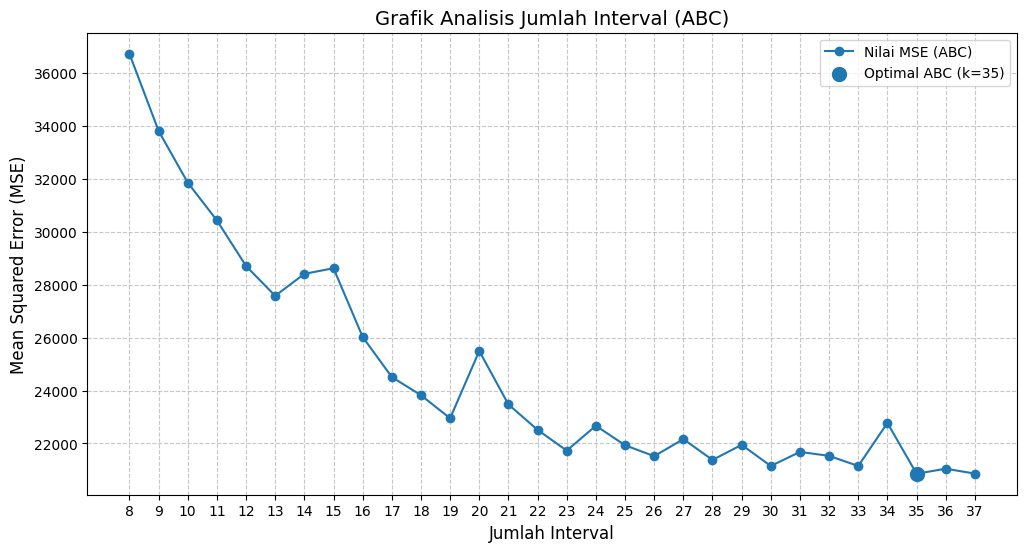

In [ ]:
#Ambil hasil interval optimal (ABC)
intervals = [item['interval'] for item in rekap_hasil_abc]
mse_values = [item['mse'] for item in rekap_hasil_abc]

#Titik optimal
min_mse = min(mse_values)
best_k = intervals[mse_values.index(min_mse)]

#Plot
plt.figure(figsize=(12, 6))
plt.plot(intervals, mse_values, marker='o', linestyle='-', label='Nilai MSE (ABC)')

#Tandai titik optimal
plt.scatter(best_k, min_mse, s=100, label=f'Optimal ABC (k={best_k})', zorder=5)

plt.title('Grafik Analisis Jumlah Interval (ABC)', fontsize=14)
plt.xlabel('Jumlah Interval', fontsize=12)
plt.ylabel('Mean Squared Error (MSE)', fontsize=12)
plt.xticks(intervals)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

plt.show()

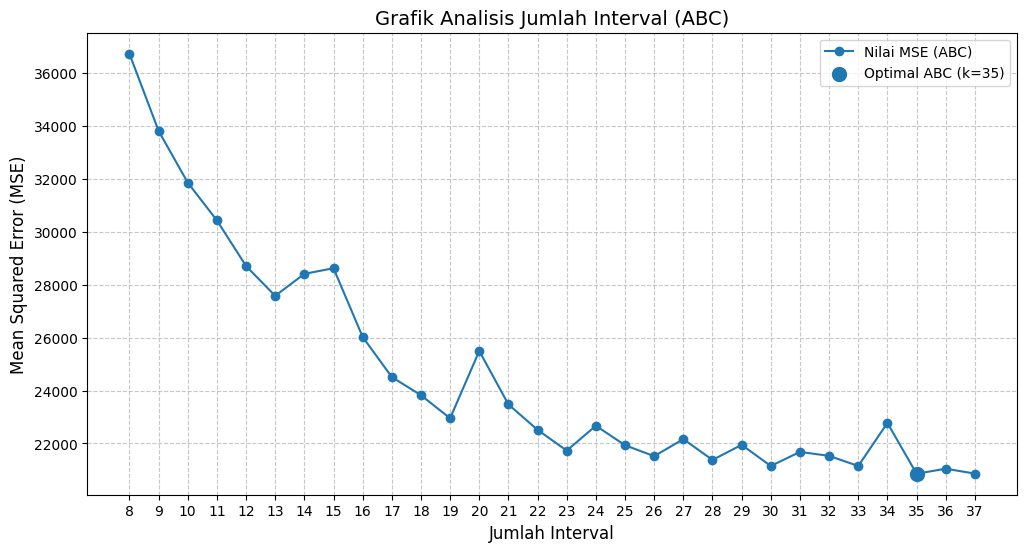

In [ ]:
#Ambil hasil interval optimal (ABC)
intervals = [item['interval'] for item in rekap_hasil_abc]
mse_values = [item['mse'] for item in rekap_hasil_abc]

#Titik optimal
min_mse = min(mse_values)
best_k = intervals[mse_values.index(min_mse)]

#Plot
plt.figure(figsize=(12, 6))
plt.plot(intervals, mse_values, marker='o', linestyle='-', label='Nilai MSE (ABC)')

#Tandai titik optimal
plt.scatter(best_k, min_mse, s=100, label=f'Optimal ABC (k={best_k})', zorder=5)

plt.title('Grafik Analisis Jumlah Interval (ABC)', fontsize=14)
plt.xlabel('Jumlah Interval', fontsize=12)
plt.ylabel('Mean Squared Error (MSE)', fontsize=12)
plt.xticks(intervals)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

plt.show()

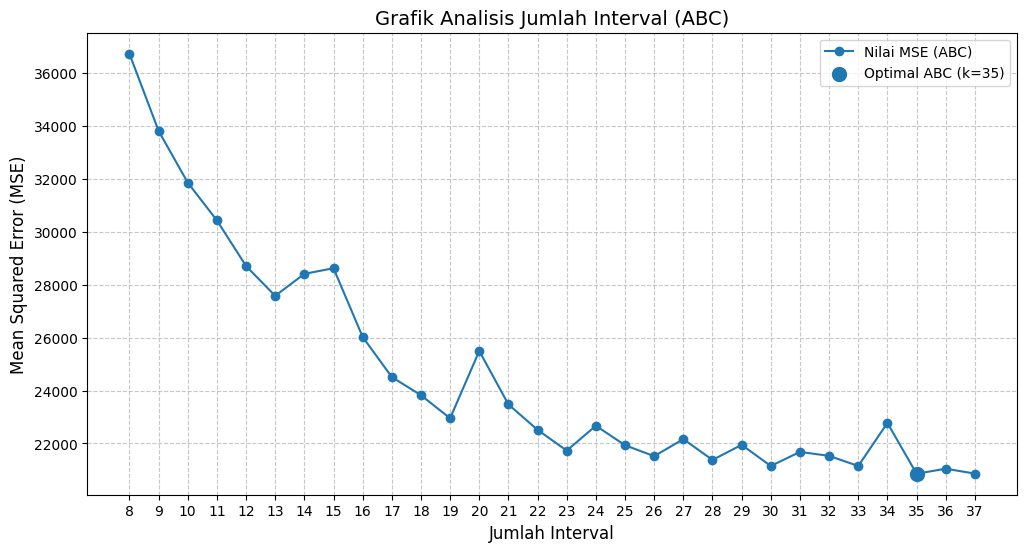

In [ ]:
#Ambil hasil interval optimal (ABC)
intervals = [item['interval'] for item in rekap_hasil_abc]
mse_values = [item['mse'] for item in rekap_hasil_abc]

#Titik optimal
min_mse = min(mse_values)
best_k = intervals[mse_values.index(min_mse)]

#Plot
plt.figure(figsize=(12, 6))
plt.plot(intervals, mse_values, marker='o', linestyle='-', label='Nilai MSE (ABC)')

#Tandai titik optimal
plt.scatter(best_k, min_mse, s=100, label=f'Optimal ABC (k={best_k})', zorder=5)

plt.title('Grafik Analisis Jumlah Interval (ABC)', fontsize=14)
plt.xlabel('Jumlah Interval', fontsize=12)
plt.ylabel('Mean Squared Error (MSE)', fontsize=12)
plt.xticks(intervals)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

plt.show()

# ***Fuzzy Time Series Cheng*-ABC**

### Interval Optimal dan Nilai Tengah

In [ ]:
#Interval Optimal Hasil ABC
boundaries_abc = sorted(hasiloptabc['boundary'])

bBawah_abc = [xmin] + list(boundaries_abc)
bAtas_abc  = list(boundaries_abc) + [xmax]

#Batas Bawah dan Batas Atas
bBawah_abc = [int(round(x)) for x in bBawah_abc]
bAtas_abc  = [int(round(x)) for x in bAtas_abc]

#Nilai tengah
tengah_abc = [int(round((bBawah_abc[i] + bAtas_abc[i]) / 2)) for i in range(len(bBawah_abc))]

#Kelas
K_abc = len(bBawah_abc)
kelas_abc = [f"A{i+1}" for i in range(K_abc)]

#Tampilkan
print("\nInterval dan Nilai Tengah (ABC):\n")
for i in range(K_abc):
    print(f"{kelas_abc[i]:2s} → {bBawah_abc[i]} - {bAtas_abc[i]} | Midpoint: {tengah_abc[i]}")


Interval dan Nilai Tengah (ABC):

A1 → 11500 - 11562 | Midpoint: 11531
A2 → 11562 - 11637 | Midpoint: 11600
A3 → 11637 - 11661 | Midpoint: 11649
A4 → 11661 - 11731 | Midpoint: 11696
A5 → 11731 - 11763 | Midpoint: 11747
A6 → 11763 - 11829 | Midpoint: 11796
A7 → 11829 - 11872 | Midpoint: 11850
A8 → 11872 - 11901 | Midpoint: 11886
A9 → 11901 - 12046 | Midpoint: 11974
A10 → 12046 - 12056 | Midpoint: 12051
A11 → 12056 - 12120 | Midpoint: 12088
A12 → 12120 - 12241 | Midpoint: 12180
A13 → 12241 - 12280 | Midpoint: 12260
A14 → 12280 - 12438 | Midpoint: 12359
A15 → 12438 - 12727 | Midpoint: 12582
A16 → 12727 - 12987 | Midpoint: 12857
A17 → 12987 - 13233 | Midpoint: 13110
A18 → 13233 - 13281 | Midpoint: 13257
A19 → 13281 - 13341 | Midpoint: 13311
A20 → 13341 - 13362 | Midpoint: 13352
A21 → 13362 - 13420 | Midpoint: 13391
A22 → 13420 - 13463 | Midpoint: 13442
A23 → 13463 - 13603 | Midpoint: 13533
A24 → 13603 - 13732 | Midpoint: 13668
A25 → 13732 - 13760 | Midpoint: 13746
A26 → 13760 - 14076 | Mi

In [ ]:
#Interval Optimal Hasil ABC
boundaries_abc = sorted(hasiloptabc['boundary'])

bBawah_abc = [xmin] + list(boundaries_abc)
bAtas_abc  = list(boundaries_abc) + [xmax]

#Batas Bawah dan Batas Atas
bBawah_abc = [int(round(x)) for x in bBawah_abc]
bAtas_abc  = [int(round(x)) for x in bAtas_abc]

#Nilai tengah
tengah_abc = [int(round((bBawah_abc[i] + bAtas_abc[i]) / 2)) for i in range(len(bBawah_abc))]

#Kelas
K_abc = len(bBawah_abc)
kelas_abc = [f"A{i+1}" for i in range(K_abc)]

#Tampilkan
print("\nInterval dan Nilai Tengah (ABC):\n")
for i in range(K_abc):
    print(f"{kelas_abc[i]:2s} → {bBawah_abc[i]} - {bAtas_abc[i]} | Midpoint: {tengah_abc[i]}")


Interval dan Nilai Tengah (ABC):

A1 → 11500 - 11562 | Midpoint: 11531
A2 → 11562 - 11637 | Midpoint: 11600
A3 → 11637 - 11661 | Midpoint: 11649
A4 → 11661 - 11731 | Midpoint: 11696
A5 → 11731 - 11763 | Midpoint: 11747
A6 → 11763 - 11829 | Midpoint: 11796
A7 → 11829 - 11872 | Midpoint: 11850
A8 → 11872 - 11901 | Midpoint: 11886
A9 → 11901 - 12046 | Midpoint: 11974
A10 → 12046 - 12056 | Midpoint: 12051
A11 → 12056 - 12120 | Midpoint: 12088
A12 → 12120 - 12241 | Midpoint: 12180
A13 → 12241 - 12280 | Midpoint: 12260
A14 → 12280 - 12438 | Midpoint: 12359
A15 → 12438 - 12727 | Midpoint: 12582
A16 → 12727 - 12987 | Midpoint: 12857
A17 → 12987 - 13233 | Midpoint: 13110
A18 → 13233 - 13281 | Midpoint: 13257
A19 → 13281 - 13341 | Midpoint: 13311
A20 → 13341 - 13362 | Midpoint: 13352
A21 → 13362 - 13420 | Midpoint: 13391
A22 → 13420 - 13463 | Midpoint: 13442
A23 → 13463 - 13603 | Midpoint: 13533
A24 → 13603 - 13732 | Midpoint: 13668
A25 → 13732 - 13760 | Midpoint: 13746
A26 → 13760 - 14076 | Mi

### Fuzzifikasi *Training*

In [ ]:
#Fuzzifikasi Training
print("\nFuzzifikasi Training (ABC)\n")

fuzzy_train_abc = []

for x in train_data:
    for i in range(K_abc):

        if i == K_abc - 1:
            if bBawah_abc[i] <= x <= bAtas_abc[i]:
                fuzzy_train_abc.append(kelas_abc[i])
                break
        else:
            if bBawah_abc[i] <= x < bAtas_abc[i]:
                fuzzy_train_abc.append(kelas_abc[i])
                break

#Tampilkan Hasil
print("Hasil Fuzzifikasi Training:", fuzzy_train_abc)


Fuzzifikasi Training (ABC)

Hasil Fuzzifikasi Training: ['A11', 'A10', 'A8', 'A5', 'A4', 'A4', 'A4', 'A4', 'A4', 'A5', 'A5', 'A1', 'A8', 'A8', 'A6', 'A4', 'A4', 'A4', 'A4', 'A4', 'A4', 'A5', 'A5', 'A1', 'A7', 'A7', 'A7', 'A9', 'A17', 'A7', 'A7', 'A7', 'A6', 'A6', 'A6', 'A9', 'A6', 'A6', 'A6', 'A5', 'A5', 'A5', 'A4', 'A3', 'A3', 'A3', 'A3', 'A2', 'A6', 'A6', 'A6', 'A5', 'A5', 'A5', 'A5', 'A8', 'A11', 'A12', 'A13', 'A15', 'A16', 'A18', 'A20', 'A21', 'A22', 'A23', 'A23', 'A24', 'A27', 'A28', 'A28', 'A25', 'A29', 'A34', 'A35']


In [ ]:
#Fuzzifikasi Training
print("\nFuzzifikasi Training (ABC)\n")

fuzzy_train_abc = []

for x in train_data:
    for i in range(K_abc):

        if i == K_abc - 1:
            if bBawah_abc[i] <= x <= bAtas_abc[i]:
                fuzzy_train_abc.append(kelas_abc[i])
                break
        else:
            if bBawah_abc[i] <= x < bAtas_abc[i]:
                fuzzy_train_abc.append(kelas_abc[i])
                break

#Tampilkan Hasil
print("Hasil Fuzzifikasi Training:", fuzzy_train_abc)


Fuzzifikasi Training (ABC)

Hasil Fuzzifikasi Training: ['A11', 'A10', 'A8', 'A5', 'A4', 'A4', 'A4', 'A4', 'A4', 'A5', 'A5', 'A1', 'A8', 'A8', 'A6', 'A4', 'A4', 'A4', 'A4', 'A4', 'A4', 'A5', 'A5', 'A1', 'A7', 'A7', 'A7', 'A9', 'A17', 'A7', 'A7', 'A7', 'A6', 'A6', 'A6', 'A9', 'A6', 'A6', 'A6', 'A5', 'A5', 'A5', 'A4', 'A3', 'A3', 'A3', 'A3', 'A2', 'A6', 'A6', 'A6', 'A5', 'A5', 'A5', 'A5', 'A8', 'A11', 'A12', 'A13', 'A15', 'A16', 'A18', 'A20', 'A21', 'A22', 'A23', 'A23', 'A24', 'A27', 'A28', 'A28', 'A25', 'A29', 'A34', 'A35']


### FLR

In [ ]:
#FLR
print("\nFLR (ABC)\n")

flr_abc = [(fuzzy_train_abc[i-1], fuzzy_train_abc[i]) for i in range(1, len(fuzzy_train_abc))]

#Tampilkan Hasil
print("Hasil FLR:", flr_abc)


FLR (ABC)

Hasil FLR: [('A11', 'A10'), ('A10', 'A8'), ('A8', 'A5'), ('A5', 'A4'), ('A4', 'A4'), ('A4', 'A4'), ('A4', 'A4'), ('A4', 'A4'), ('A4', 'A5'), ('A5', 'A5'), ('A5', 'A1'), ('A1', 'A8'), ('A8', 'A8'), ('A8', 'A6'), ('A6', 'A4'), ('A4', 'A4'), ('A4', 'A4'), ('A4', 'A4'), ('A4', 'A4'), ('A4', 'A4'), ('A4', 'A5'), ('A5', 'A5'), ('A5', 'A1'), ('A1', 'A7'), ('A7', 'A7'), ('A7', 'A7'), ('A7', 'A9'), ('A9', 'A17'), ('A17', 'A7'), ('A7', 'A7'), ('A7', 'A7'), ('A7', 'A6'), ('A6', 'A6'), ('A6', 'A6'), ('A6', 'A9'), ('A9', 'A6'), ('A6', 'A6'), ('A6', 'A6'), ('A6', 'A5'), ('A5', 'A5'), ('A5', 'A5'), ('A5', 'A4'), ('A4', 'A3'), ('A3', 'A3'), ('A3', 'A3'), ('A3', 'A3'), ('A3', 'A2'), ('A2', 'A6'), ('A6', 'A6'), ('A6', 'A6'), ('A6', 'A5'), ('A5', 'A5'), ('A5', 'A5'), ('A5', 'A5'), ('A5', 'A8'), ('A8', 'A11'), ('A11', 'A12'), ('A12', 'A13'), ('A13', 'A15'), ('A15', 'A16'), ('A16', 'A18'), ('A18', 'A20'), ('A20', 'A21'), ('A21', 'A22'), ('A22', 'A23'), ('A23', 'A23'), ('A23', 'A24'), ('A24', 'A

In [ ]:
#FLR
print("\nFLR (ABC)\n")

flr_abc = [(fuzzy_train_abc[i-1], fuzzy_train_abc[i]) for i in range(1, len(fuzzy_train_abc))]

#Tampilkan Hasil
print("Hasil FLR:", flr_abc)


FLR (ABC)

Hasil FLR: [('A11', 'A10'), ('A10', 'A8'), ('A8', 'A5'), ('A5', 'A4'), ('A4', 'A4'), ('A4', 'A4'), ('A4', 'A4'), ('A4', 'A4'), ('A4', 'A5'), ('A5', 'A5'), ('A5', 'A1'), ('A1', 'A8'), ('A8', 'A8'), ('A8', 'A6'), ('A6', 'A4'), ('A4', 'A4'), ('A4', 'A4'), ('A4', 'A4'), ('A4', 'A4'), ('A4', 'A4'), ('A4', 'A5'), ('A5', 'A5'), ('A5', 'A1'), ('A1', 'A7'), ('A7', 'A7'), ('A7', 'A7'), ('A7', 'A9'), ('A9', 'A17'), ('A17', 'A7'), ('A7', 'A7'), ('A7', 'A7'), ('A7', 'A6'), ('A6', 'A6'), ('A6', 'A6'), ('A6', 'A9'), ('A9', 'A6'), ('A6', 'A6'), ('A6', 'A6'), ('A6', 'A5'), ('A5', 'A5'), ('A5', 'A5'), ('A5', 'A4'), ('A4', 'A3'), ('A3', 'A3'), ('A3', 'A3'), ('A3', 'A3'), ('A3', 'A2'), ('A2', 'A6'), ('A6', 'A6'), ('A6', 'A6'), ('A6', 'A5'), ('A5', 'A5'), ('A5', 'A5'), ('A5', 'A5'), ('A5', 'A8'), ('A8', 'A11'), ('A11', 'A12'), ('A12', 'A13'), ('A13', 'A15'), ('A15', 'A16'), ('A16', 'A18'), ('A18', 'A20'), ('A20', 'A21'), ('A21', 'A22'), ('A22', 'A23'), ('A23', 'A23'), ('A23', 'A24'), ('A24', 'A

### FLRG

In [ ]:
#FLRG
print("\nFLRG (ABC)\n")

flrg_abc = {}
for a, b in flr_abc:
    if a not in flrg_abc:
        flrg_abc[a] = []
    flrg_abc[a].append(b)

#Tampilkan Hasil
for key in flrg_abc:
    print(f"{key} → {flrg_abc[key]}")


FLRG (ABC)

A11 → ['A10', 'A12']
A10 → ['A8']
A8 → ['A5', 'A8', 'A6', 'A11']
A5 → ['A4', 'A5', 'A1', 'A5', 'A1', 'A5', 'A5', 'A4', 'A5', 'A5', 'A5', 'A8']
A4 → ['A4', 'A4', 'A4', 'A4', 'A5', 'A4', 'A4', 'A4', 'A4', 'A4', 'A5', 'A3']
A1 → ['A8', 'A7']
A6 → ['A4', 'A6', 'A6', 'A9', 'A6', 'A6', 'A5', 'A6', 'A6', 'A5']
A7 → ['A7', 'A7', 'A9', 'A7', 'A7', 'A6']
A9 → ['A17', 'A6']
A17 → ['A7']
A3 → ['A3', 'A3', 'A3', 'A2']
A2 → ['A6']
A12 → ['A13']
A13 → ['A15']
A15 → ['A16']
A16 → ['A18']
A18 → ['A20']
A20 → ['A21']
A21 → ['A22']
A22 → ['A23']
A23 → ['A23', 'A24']
A24 → ['A27']
A27 → ['A28']
A28 → ['A28', 'A25']
A25 → ['A29']
A29 → ['A34']
A34 → ['A35']


In [ ]:
#FLRG
print("\nFLRG (ABC)\n")

flrg_abc = {}
for a, b in flr_abc:
    if a not in flrg_abc:
        flrg_abc[a] = []
    flrg_abc[a].append(b)

#Tampilkan Hasil
for key in flrg_abc:
    print(f"{key} → {flrg_abc[key]}")


FLRG (ABC)

A11 → ['A10', 'A12']
A10 → ['A8']
A8 → ['A5', 'A8', 'A6', 'A11']
A5 → ['A4', 'A5', 'A1', 'A5', 'A1', 'A5', 'A5', 'A4', 'A5', 'A5', 'A5', 'A8']
A4 → ['A4', 'A4', 'A4', 'A4', 'A5', 'A4', 'A4', 'A4', 'A4', 'A4', 'A5', 'A3']
A1 → ['A8', 'A7']
A6 → ['A4', 'A6', 'A6', 'A9', 'A6', 'A6', 'A5', 'A6', 'A6', 'A5']
A7 → ['A7', 'A7', 'A9', 'A7', 'A7', 'A6']
A9 → ['A17', 'A6']
A17 → ['A7']
A3 → ['A3', 'A3', 'A3', 'A2']
A2 → ['A6']
A12 → ['A13']
A13 → ['A15']
A15 → ['A16']
A16 → ['A18']
A18 → ['A20']
A20 → ['A21']
A21 → ['A22']
A22 → ['A23']
A23 → ['A23', 'A24']
A24 → ['A27']
A27 → ['A28']
A28 → ['A28', 'A25']
A25 → ['A29']
A29 → ['A34']
A34 → ['A35']


### Pembobotan

In [ ]:
#Pembobotan
print("\nPembobotan (ABC)\n")

bobot_abc = {}
for key, v in flrg_abc.items():
    c = Counter(v)
    total = sum(c.values())
    bobot_abc[key] = {kk: round(c[kk]/total, 3) for kk in c}

#Tampilkan Hasil
for key in bobot_abc:
    print(f"{key} → {bobot_abc[key]}")


Pembobotan (ABC)

A11 → {'A10': 0.5, 'A12': 0.5}
A10 → {'A8': 1.0}
A8 → {'A5': 0.25, 'A8': 0.25, 'A6': 0.25, 'A11': 0.25}
A5 → {'A4': 0.167, 'A5': 0.583, 'A1': 0.167, 'A8': 0.083}
A4 → {'A4': 0.75, 'A5': 0.167, 'A3': 0.083}
A1 → {'A8': 0.5, 'A7': 0.5}
A6 → {'A4': 0.1, 'A6': 0.6, 'A9': 0.1, 'A5': 0.2}
A7 → {'A7': 0.667, 'A9': 0.167, 'A6': 0.167}
A9 → {'A17': 0.5, 'A6': 0.5}
A17 → {'A7': 1.0}
A3 → {'A3': 0.75, 'A2': 0.25}
A2 → {'A6': 1.0}
A12 → {'A13': 1.0}
A13 → {'A15': 1.0}
A15 → {'A16': 1.0}
A16 → {'A18': 1.0}
A18 → {'A20': 1.0}
A20 → {'A21': 1.0}
A21 → {'A22': 1.0}
A22 → {'A23': 1.0}
A23 → {'A23': 0.5, 'A24': 0.5}
A24 → {'A27': 1.0}
A27 → {'A28': 1.0}
A28 → {'A28': 0.5, 'A25': 0.5}
A25 → {'A29': 1.0}
A29 → {'A34': 1.0}
A34 → {'A35': 1.0}


In [ ]:
#Pembobotan
print("\nPembobotan (ABC)\n")

bobot_abc = {}
for key, v in flrg_abc.items():
    c = Counter(v)
    total = sum(c.values())
    bobot_abc[key] = {kk: round(c[kk]/total, 3) for kk in c}

#Tampilkan Hasil
for key in bobot_abc:
    print(f"{key} → {bobot_abc[key]}")


Pembobotan (ABC)

A11 → {'A10': 0.5, 'A12': 0.5}
A10 → {'A8': 1.0}
A8 → {'A5': 0.25, 'A8': 0.25, 'A6': 0.25, 'A11': 0.25}
A5 → {'A4': 0.167, 'A5': 0.583, 'A1': 0.167, 'A8': 0.083}
A4 → {'A4': 0.75, 'A5': 0.167, 'A3': 0.083}
A1 → {'A8': 0.5, 'A7': 0.5}
A6 → {'A4': 0.1, 'A6': 0.6, 'A9': 0.1, 'A5': 0.2}
A7 → {'A7': 0.667, 'A9': 0.167, 'A6': 0.167}
A9 → {'A17': 0.5, 'A6': 0.5}
A17 → {'A7': 1.0}
A3 → {'A3': 0.75, 'A2': 0.25}
A2 → {'A6': 1.0}
A12 → {'A13': 1.0}
A13 → {'A15': 1.0}
A15 → {'A16': 1.0}
A16 → {'A18': 1.0}
A18 → {'A20': 1.0}
A20 → {'A21': 1.0}
A21 → {'A22': 1.0}
A22 → {'A23': 1.0}
A23 → {'A23': 0.5, 'A24': 0.5}
A24 → {'A27': 1.0}
A27 → {'A28': 1.0}
A28 → {'A28': 0.5, 'A25': 0.5}
A25 → {'A29': 1.0}
A29 → {'A34': 1.0}
A34 → {'A35': 1.0}


### Defuzzifikasi

In [ ]:
#Defuzzifikasi
print("\nDefuzzifikasi (ABC)\n")

defuzz_abc = {}
for key in bobot_abc:
    val = 0
    for tujuan in bobot_abc[key]:
        idx = kelas_abc.index(tujuan)
        val += bobot_abc[key][tujuan] * tengah_abc[idx]
    defuzz_abc[key] = round(val, 3)

#Tampilkan Hasil
for key in defuzz_abc:
    print(f"{key} → {defuzz_abc[key]:.3f}")


Defuzzifikasi (ABC)

A11 → 12115.500
A10 → 11886.000
A8 → 11879.250
A5 → 11713.948
A4 → 11700.616
A1 → 11868.000
A6 → 11794.000
A7 → 11873.540
A9 → 12453.000
A17 → 11850.000
A3 → 11636.750
A2 → 11796.000
A12 → 12260.000
A13 → 12582.000
A15 → 12857.000
A16 → 13257.000
A18 → 13352.000
A20 → 13391.000
A21 → 13442.000
A22 → 13533.000
A23 → 13600.500
A24 → 14338.000
A27 → 14662.000
A28 → 14204.000
A25 → 14858.000
A29 → 15755.000
A34 → 15942.000


In [ ]:
#Defuzzifikasi
print("\nDefuzzifikasi (ABC)\n")

defuzz_abc = {}
for key in bobot_abc:
    val = 0
    for tujuan in bobot_abc[key]:
        idx = kelas_abc.index(tujuan)
        val += bobot_abc[key][tujuan] * tengah_abc[idx]
    defuzz_abc[key] = round(val, 3)

#Tampilkan Hasil
for key in defuzz_abc:
    print(f"{key} → {defuzz_abc[key]:.3f}")


Defuzzifikasi (ABC)

A11 → 12115.500
A10 → 11886.000
A8 → 11879.250
A5 → 11713.948
A4 → 11700.616
A1 → 11868.000
A6 → 11794.000
A7 → 11873.540
A9 → 12453.000
A17 → 11850.000
A3 → 11636.750
A2 → 11796.000
A12 → 12260.000
A13 → 12582.000
A15 → 12857.000
A16 → 13257.000
A18 → 13352.000
A20 → 13391.000
A21 → 13442.000
A22 → 13533.000
A23 → 13600.500
A24 → 14338.000
A27 → 14662.000
A28 → 14204.000
A25 → 14858.000
A29 → 15755.000
A34 → 15942.000


### Prediksi *Training*

In [ ]:
#Prediksi Training
print("\nPrediksi Training (ABC)\n")

pred_train_abc = [None]

for i in range(1, len(fuzzy_train_abc)):
    prev = fuzzy_train_abc[i-1]

    if prev in defuzz_abc:
        pred_train_abc.append(defuzz_abc[prev])
    else:
        idx = kelas_abc.index(prev)
        pred_train_abc.append(tengah_abc[idx])

#Tampilkan hasil
print("Prediksi Training:", pred_train_abc)


Prediksi Training (ABC)

Prediksi Training: [None, 12115.5, 11886.0, 11879.25, 11713.948, 11700.616, 11700.616, 11700.616, 11700.616, 11700.616, 11713.948, 11713.948, 11868.0, 11879.25, 11879.25, 11794.0, 11700.616, 11700.616, 11700.616, 11700.616, 11700.616, 11700.616, 11713.948, 11713.948, 11868.0, 11873.54, 11873.54, 11873.54, 12453.0, 11850.0, 11873.54, 11873.54, 11873.54, 11794.0, 11794.0, 11794.0, 12453.0, 11794.0, 11794.0, 11794.0, 11713.948, 11713.948, 11713.948, 11700.616, 11636.75, 11636.75, 11636.75, 11636.75, 11796.0, 11794.0, 11794.0, 11794.0, 11713.948, 11713.948, 11713.948, 11713.948, 11879.25, 12115.5, 12260.0, 12582.0, 12857.0, 13257.0, 13352.0, 13391.0, 13442.0, 13533.0, 13600.5, 13600.5, 14338.0, 14662.0, 14204.0, 14204.0, 14858.0, 15755.0, 15942.0]


In [ ]:
#Prediksi Training
print("\nPrediksi Training (ABC)\n")

pred_train_abc = [None]

for i in range(1, len(fuzzy_train_abc)):
    prev = fuzzy_train_abc[i-1]

    if prev in defuzz_abc:
        pred_train_abc.append(defuzz_abc[prev])
    else:
        idx = kelas_abc.index(prev)
        pred_train_abc.append(tengah_abc[idx])

#Tampilkan hasil
print("Prediksi Training:", pred_train_abc)


Prediksi Training (ABC)

Prediksi Training: [None, 12115.5, 11886.0, 11879.25, 11713.948, 11700.616, 11700.616, 11700.616, 11700.616, 11700.616, 11713.948, 11713.948, 11868.0, 11879.25, 11879.25, 11794.0, 11700.616, 11700.616, 11700.616, 11700.616, 11700.616, 11700.616, 11713.948, 11713.948, 11868.0, 11873.54, 11873.54, 11873.54, 12453.0, 11850.0, 11873.54, 11873.54, 11873.54, 11794.0, 11794.0, 11794.0, 12453.0, 11794.0, 11794.0, 11794.0, 11713.948, 11713.948, 11713.948, 11700.616, 11636.75, 11636.75, 11636.75, 11636.75, 11796.0, 11794.0, 11794.0, 11794.0, 11713.948, 11713.948, 11713.948, 11713.948, 11879.25, 12115.5, 12260.0, 12582.0, 12857.0, 13257.0, 13352.0, 13391.0, 13442.0, 13533.0, 13600.5, 13600.5, 14338.0, 14662.0, 14204.0, 14204.0, 14858.0, 15755.0, 15942.0]


### Fuzzifikasi *Testing*

In [ ]:
#Fuzzifikasi testing
print("\nFuzzifikasi Testing (ABC)\n")

fuzzy_test_abc = []

for x in test_data:
    for i in range(K_abc):

        if i == K_abc - 1:
            if bBawah_abc[i] <= x <= bAtas_abc[i]:
                fuzzy_test_abc.append(kelas_abc[i])
                break
        else:
            if bBawah_abc[i] <= x < bAtas_abc[i]:
                fuzzy_test_abc.append(kelas_abc[i])
                break

#tampilkan Hasil
print("Fuzzifikasi Testing:", fuzzy_test_abc)


Fuzzifikasi Testing (ABC)

Fuzzifikasi Testing: ['A33', 'A31', 'A31', 'A31', 'A31', 'A31', 'A31', 'A31', 'A31', 'A31', 'A31', 'A31', 'A31', 'A31', 'A34', 'A34', 'A35', 'A34', 'A34']


In [ ]:
#Fuzzifikasi testing
print("\nFuzzifikasi Testing (ABC)\n")

fuzzy_test_abc = []

for x in test_data:
    for i in range(K_abc):

        if i == K_abc - 1:
            if bBawah_abc[i] <= x <= bAtas_abc[i]:
                fuzzy_test_abc.append(kelas_abc[i])
                break
        else:
            if bBawah_abc[i] <= x < bAtas_abc[i]:
                fuzzy_test_abc.append(kelas_abc[i])
                break

#tampilkan Hasil
print("Fuzzifikasi Testing:", fuzzy_test_abc)


Fuzzifikasi Testing (ABC)

Fuzzifikasi Testing: ['A33', 'A31', 'A31', 'A31', 'A31', 'A31', 'A31', 'A31', 'A31', 'A31', 'A31', 'A31', 'A31', 'A31', 'A34', 'A34', 'A35', 'A34', 'A34']


### Prediksi *Testing*

In [ ]:
#Prediksi Data Testing
print("\nPrediksi Testing (ABC)\n")

pred_test_abc = []
prev = fuzzy_train_abc[-1]

if prev in defuzz_abc:
    pred_test_abc.append(defuzz_abc[prev])
else:
    idx = kelas_abc.index(prev)
    pred_test_abc.append(tengah_abc[idx])

for i in range(1, len(fuzzy_test_abc)):
    prev = fuzzy_test_abc[i-1]

    if prev in defuzz_abc:
        pred_test_abc.append(defuzz_abc[prev])
    else:
        idx = kelas_abc.index(prev)
        pred_test_abc.append(tengah_abc[idx])

#Tampilkan Hasil
print("Prediksi Testing:", pred_test_abc)


Prediksi Testing (ABC)

Prediksi Testing: [15942, 15545, 15260, 15260, 15260, 15260, 15260, 15260, 15260, 15260, 15260, 15260, 15260, 15260, 15260, 15942.0, 15942.0, 15942, 15942.0]


In [ ]:
#Prediksi Data Testing
print("\nPrediksi Testing (ABC)\n")

pred_test_abc = []
prev = fuzzy_train_abc[-1]

if prev in defuzz_abc:
    pred_test_abc.append(defuzz_abc[prev])
else:
    idx = kelas_abc.index(prev)
    pred_test_abc.append(tengah_abc[idx])

for i in range(1, len(fuzzy_test_abc)):
    prev = fuzzy_test_abc[i-1]

    if prev in defuzz_abc:
        pred_test_abc.append(defuzz_abc[prev])
    else:
        idx = kelas_abc.index(prev)
        pred_test_abc.append(tengah_abc[idx])

#Tampilkan Hasil
print("Prediksi Testing:", pred_test_abc)


Prediksi Testing (ABC)

Prediksi Testing: [15942, 15545, 15260, 15260, 15260, 15260, 15260, 15260, 15260, 15260, 15260, 15260, 15260, 15260, 15260, 15942.0, 15942.0, 15942, 15942.0]


# **Evaluasi Hasil Peramalan FTS *Cheng*-ABC**

Training

In [ ]:
#Evaluasi Training MAPE
actual = np.array(train_data[1:])
forecast = np.array(pred_train_abc[1:])

mape = np.mean(np.abs((actual - forecast) / actual)) * 100

print("MAPE Training:", mape)

MAPE Training: 0.5306562581748356


In [ ]:
#Evaluasi Training MAPE
actual = np.array(train_data[1:])
forecast = np.array(pred_train_abc[1:])

mape = np.mean(np.abs((actual - forecast) / actual)) * 100

print("MAPE Training:", mape)

MAPE Training: 0.5306562581748356


In [ ]:
#Evaluasi Training MAE
actual_train = np.array(train_data[1:])
forecast_train = np.array(pred_train_abc[1:])
mae_training = np.mean(np.abs(actual_train - forecast_train))
print("MAE Training:", mae_training)

MAE Training: 66.01075675675679


In [ ]:
#Evaluasi Training MAE
actual_train = np.array(train_data[1:])
forecast_train = np.array(pred_train_abc[1:])
mae_training = np.mean(np.abs(actual_train - forecast_train))
print("MAE Training:", mae_training)

MAE Training: 66.01075675675679


In [ ]:
#Evaluasi Training RMSE
actual_train = np.array(train_data[1:])
forecast_train = np.array(pred_train_abc[1:])
rmse_training = np.sqrt(np.mean((actual_train - forecast_train)**2))
print("RMSE Training:", rmse_training)

RMSE Training: 144.48138398367396


In [ ]:
#Evaluasi Training RMSE
actual_train = np.array(train_data[1:])
forecast_train = np.array(pred_train_abc[1:])
rmse_training = np.sqrt(np.mean((actual_train - forecast_train)**2))
print("RMSE Training:", rmse_training)

RMSE Training: 144.48138398367396


Testing

In [ ]:
#Evaluasi MAPE
actual = np.array(test_data)
forecast = np.array(pred_test_abc)

mape = np.mean(np.abs((actual - forecast) / actual)) * 100

print("MAPE:", mape)

MAPE: 0.63320944537707


In [ ]:
#Evaluasi MAPE
actual = np.array(test_data)
forecast = np.array(pred_test_abc)
mape = np.mean(np.abs((actual - forecast) / actual)) * 100
print("MAPE:", mape)

MAPE: 0.63320944537707


In [ ]:
# Evaluasi Testing MAE
actual_test = np.array(test_data)
forecast_test = np.array(pred_test_abc)
mae_testing = np.mean(np.abs(actual_test - forecast_test))
print("MAE Testing :", mae_testing)

MAE Testing : 97.94736842105263


In [ ]:
# Evaluasi Testing RMSE
actual_test = np.array(test_data)
forecast_test = np.array(pred_test_abc)
rmse_testing = np.sqrt(np.mean((actual_test - forecast_test)**2))
print("RMSE Testing :", rmse_testing)

RMSE Testing : 142.8552819427667


# -----------------------------------------------------------

# **Visualisasi Perbandingan PSO dan ABC**

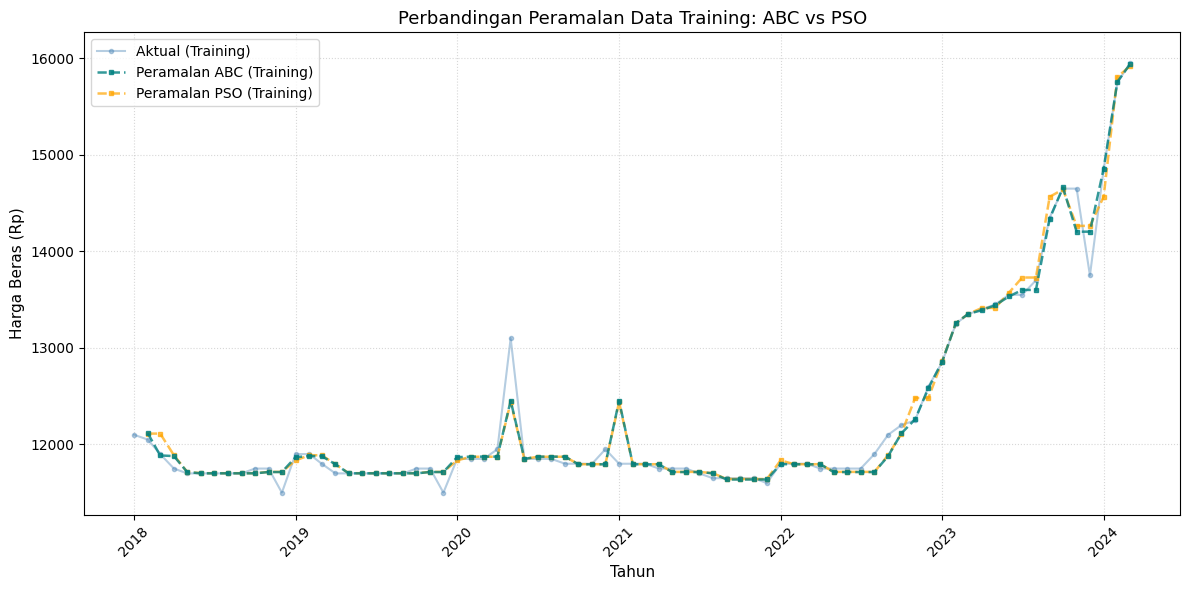

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    df['Bulan'][:len(train_data)],
    train_data,
    color='steelblue',
    alpha=0.4,
    marker='o',
    markersize=3,
    linewidth=1.5,
    label='Aktual (Training)',
    zorder=1
)

plt.plot(
    df['Bulan'][:len(pred_train_abc)],
    pred_train_abc,
    color='teal',
    alpha=0.8,
    marker='s',
    markersize=3,
    linestyle='--',
    linewidth=1.8,
    label='Peramalan ABC (Training)',
    zorder=3
)

plt.plot(
    df['Bulan'][:len(pred_train_pso)],
    pred_train_pso,
    color='orange',
    alpha=0.7,
    marker='s',
    markersize=3,
    linestyle='--',
    linewidth=1.8,
    label='Peramalan PSO (Training)',
    zorder=2
)

all_train_vals = list(train_data) + \
                 [x for x in pred_train_abc if x is not None] + \
                 [x for x in pred_train_pso if x is not None]

y_min_val = min(all_train_vals)
y_max_val = max(all_train_vals)
plt.ylim(y_min_val * 0.98, y_max_val * 1.02)

plt.xlabel('Tahun', fontsize=11)
plt.ylabel('Harga Beras (Rp)', fontsize=11)
plt.title('Perbandingan Peramalan Data Training: ABC vs PSO', fontsize=13)

plt.legend(loc='best')
plt.grid(True, linestyle=':', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

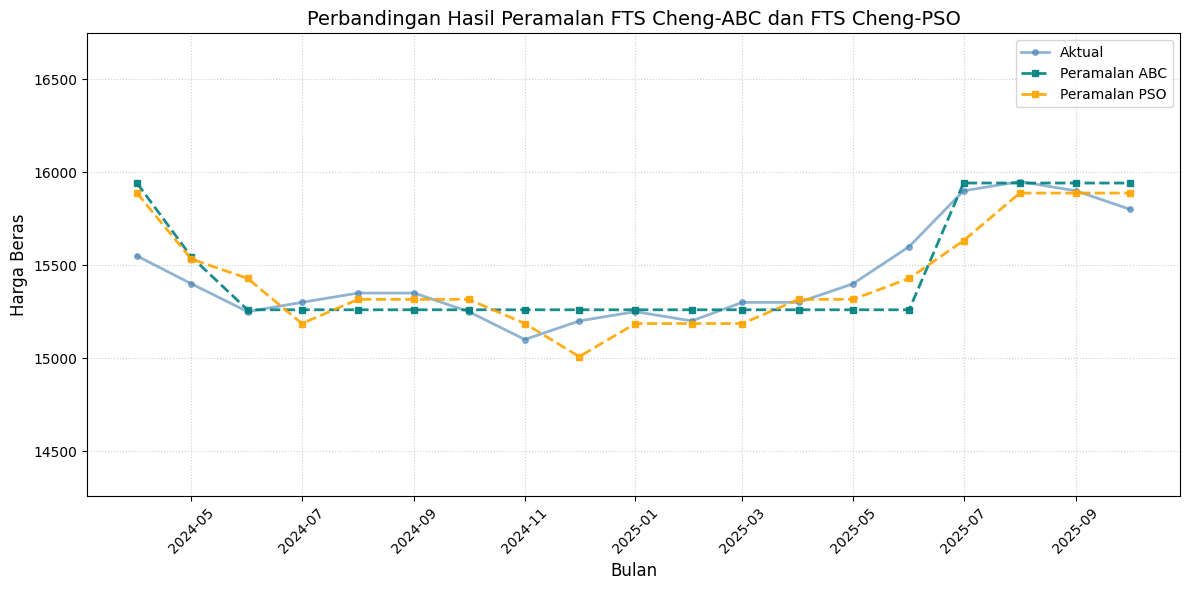

In [ ]:
# @title
#Plot perbandingan data testing pso dan abc
plt.figure(figsize=(12, 6))
#data testing
plt.plot(
    df['Bulan'][-len(test_data):],
    test_data,
    color='steelblue',
    alpha=0.6,
    marker='o',
    markersize=4,
    linewidth=2,
    label='Aktual'
)
#predtestabc
plt.plot(
    df['Bulan'][-len(pred_test_abc):],
    pred_test_abc,
    color='teal',
    alpha=0.9,
    marker='s',
    markersize=4,
    linestyle='--',
    linewidth=2,
    label='Peramalan ABC'
)
#predtestpso
plt.plot(
    df['Bulan'][-len(pred_test_pso):],
    pred_test_pso,
    color='orange',
    alpha=0.9,
    marker='s',
    markersize=4,
    linestyle='--',
    linewidth=2,
    label='Peramalan PSO'
)
all_values = list(test_data) + list(pred_test_abc) + list(pred_test_pso)
y_min, y_max = min(all_values), max(all_values)
plt.ylim(y_min * 0.95, y_max * 1.05)
#Label dan Judul
plt.xlabel('Bulan', fontsize=12)
plt.ylabel('Harga Beras', fontsize=12)
plt.title('Perbandingan Hasil Peramalan FTS Cheng-ABC dan FTS Cheng-PSO', fontsize=14)
plt.legend(loc='best', frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

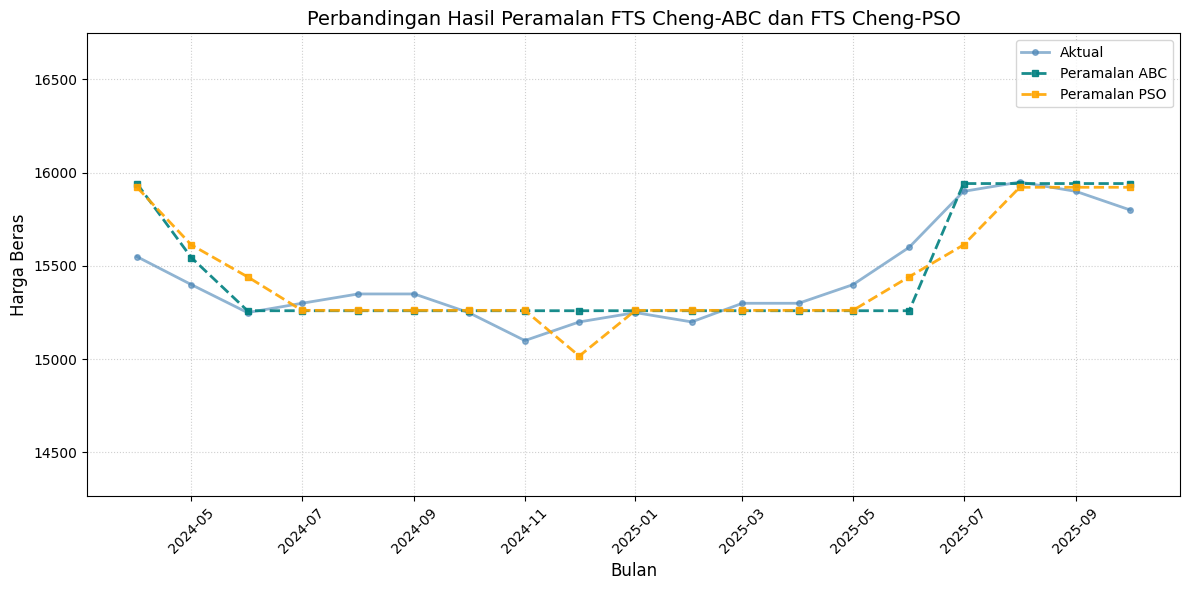

In [ ]:
#Plot perbandingan data testing pso dan abc
plt.figure(figsize=(12, 6))
#data testing
plt.plot(
    df['Bulan'][-len(test_data):],
    test_data,
    color='steelblue',
    alpha=0.6,
    marker='o',
    markersize=4,
    linewidth=2,
    label='Aktual'
)
#predtestabc
plt.plot(
    df['Bulan'][-len(pred_test_abc):],
    pred_test_abc,
    color='teal',
    alpha=0.9,
    marker='s',
    markersize=4,
    linestyle='--',
    linewidth=2,
    label='Peramalan ABC'
)
#predtestpso
plt.plot(
    df['Bulan'][-len(pred_test_pso):],
    pred_test_pso,
    color='orange',
    alpha=0.9,
    marker='s',
    markersize=4,
    linestyle='--',
    linewidth=2,
    label='Peramalan PSO'
)
all_values = list(test_data) + list(pred_test_abc) + list(pred_test_pso)
y_min, y_max = min(all_values), max(all_values)
plt.ylim(y_min * 0.95, y_max * 1.05)
#Label dan Judul
plt.xlabel('Bulan', fontsize=12)
plt.ylabel('Harga Beras', fontsize=12)
plt.title('Perbandingan Hasil Peramalan FTS Cheng-ABC dan FTS Cheng-PSO', fontsize=14)
plt.legend(loc='best', frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

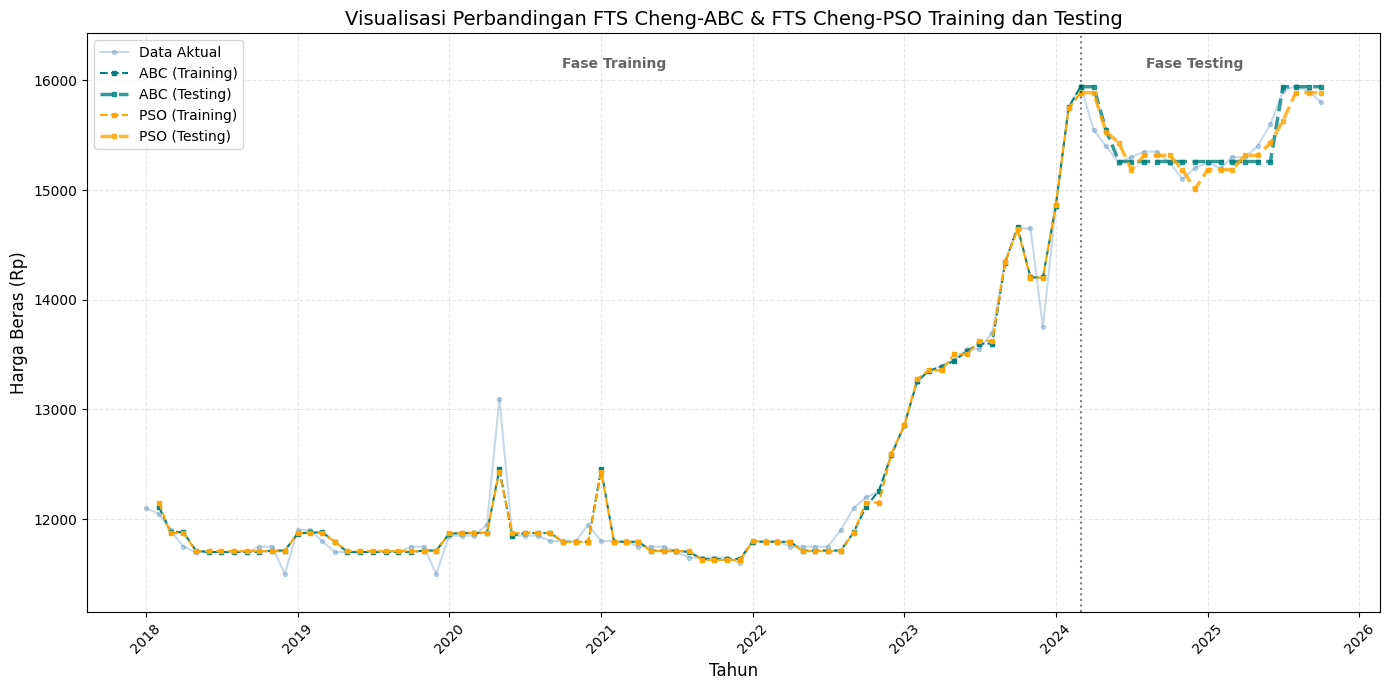

In [ ]:
# @title
plt.figure(figsize=(14, 7))

plt.plot(
    df['Bulan'],
    df['Harga'],
    color='steelblue',
    alpha=0.3,
    marker='o',
    markersize=3,
    label='Data Aktual',
    zorder=1
)

split_idx = len(pred_train_abc) - 1
idx_testing_sambung = df['Bulan'][split_idx : ]

pred_testing_sambung_abc = [pred_train_abc[-1]] + list(pred_test_abc)
pred_testing_sambung_pso = [pred_train_pso[-1]] + list(pred_test_pso)

plt.plot(
    df['Bulan'][:len(pred_train_abc)],
    pred_train_abc,
    color='teal',
    marker='s',
    markersize=3,
    linestyle='--',
    linewidth=1.5,
    label='ABC (Training)',
    zorder=2
)
plt.plot(
    idx_testing_sambung,
    pred_testing_sambung_abc,
    color='teal',
    alpha=0.8,
    marker='s',
    markersize=3,
    linestyle='--',
    linewidth=2.5,
    label='ABC (Testing)',
    zorder=4
)

plt.plot(
    df['Bulan'][:len(pred_train_pso)],
    pred_train_pso,
    color='orange',
    marker='s',
    markersize=3,
    linestyle='--',
    linewidth=1.5,
    label='PSO (Training)',
    zorder=3
)
plt.plot(
    idx_testing_sambung,
    pred_testing_sambung_pso,
    color='orange',
    alpha=0.8,
    marker='s',
    markersize=3,
    linestyle='--',
    linewidth=2.5,
    label='PSO (Testing)',
    zorder=5
)

cut_date = df['Bulan'].iloc[split_idx]
plt.axvline(x=cut_date, color='black', linestyle=':', alpha=0.5, zorder=6)

plt.text(df['Bulan'].iloc[split_idx//2], df['Harga'].max() * 1.01, 'Fase Training', ha='center', fontweight='bold', alpha=0.6)
plt.text(df['Bulan'].iloc[split_idx + (len(pred_test_abc)//2)], df['Harga'].max() * 1.01, 'Fase Testing', ha='center', fontweight='bold', alpha=0.6)

raw_values = list(pred_train_abc) + list(pred_test_abc) + list(pred_train_pso) + list(pred_test_pso)

clean_predicted = [x for x in raw_values if x is not None]

if clean_predicted:
    y_min_val = min(df['Harga'].min(), min(clean_predicted))
    y_max_val = max(df['Harga'].max(), max(clean_predicted))
else:
    y_min_val = df['Harga'].min()
    y_max_val = df['Harga'].max()

plt.ylim(y_min_val * 0.97, y_max_val * 1.03)

plt.xlabel('Tahun', fontsize=12)
plt.ylabel('Harga Beras (Rp)', fontsize=12)
plt.title('Visualisasi Perbandingan FTS Cheng-ABC & FTS Cheng-PSO Training dan Testing', fontsize=14)

plt.legend(loc='upper left', frameon=True, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

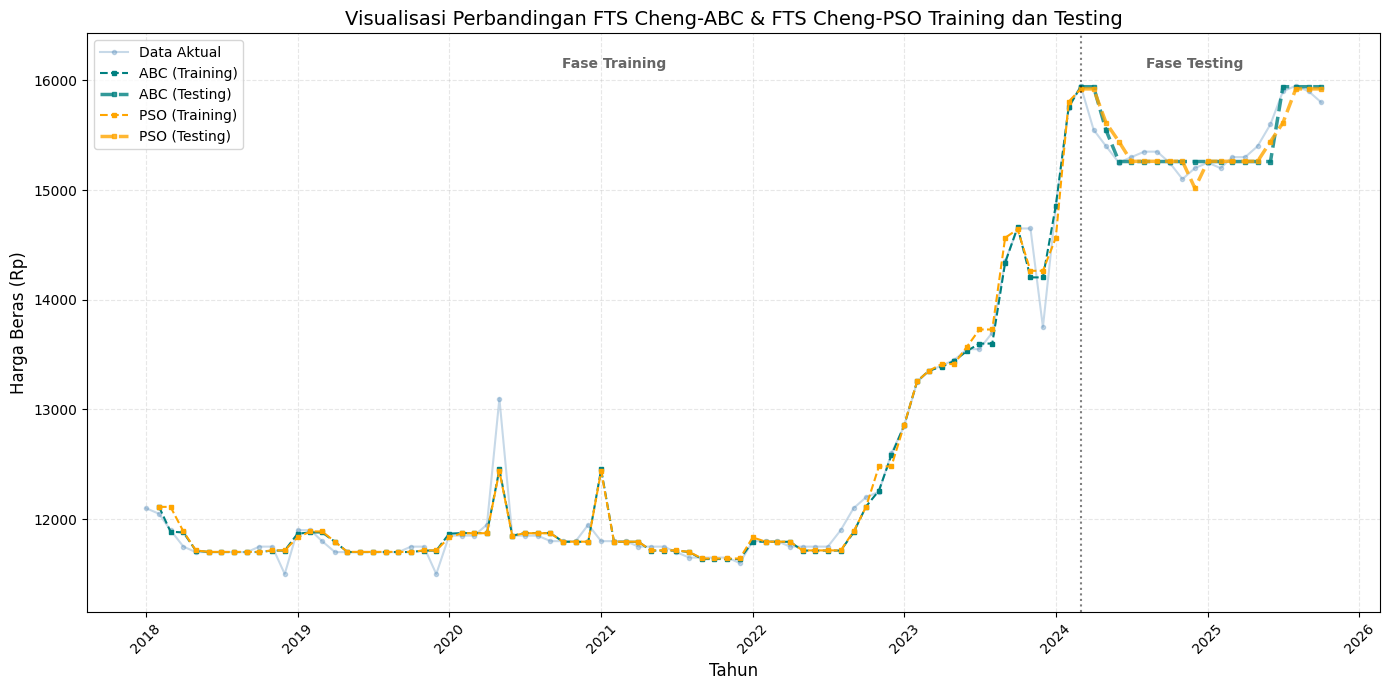

In [ ]:
plt.figure(figsize=(14, 7))

plt.plot(
    df['Bulan'],
    df['Harga'],
    color='steelblue',
    alpha=0.3,
    marker='o',
    markersize=3,
    label='Data Aktual',
    zorder=1
)

split_idx = len(pred_train_abc) - 1
idx_testing_sambung = df['Bulan'][split_idx : ]

pred_testing_sambung_abc = [pred_train_abc[-1]] + list(pred_test_abc)
pred_testing_sambung_pso = [pred_train_pso[-1]] + list(pred_test_pso)

plt.plot(
    df['Bulan'][:len(pred_train_abc)],
    pred_train_abc,
    color='teal',
    marker='s',
    markersize=3,
    linestyle='--',
    linewidth=1.5,
    label='ABC (Training)',
    zorder=2
)
plt.plot(
    idx_testing_sambung,
    pred_testing_sambung_abc,
    color='teal',
    alpha=0.8,
    marker='s',
    markersize=3,
    linestyle='--',
    linewidth=2.5,
    label='ABC (Testing)',
    zorder=4
)

plt.plot(
    df['Bulan'][:len(pred_train_pso)],
    pred_train_pso,
    color='orange',
    marker='s',
    markersize=3,
    linestyle='--',
    linewidth=1.5,
    label='PSO (Training)',
    zorder=3
)
plt.plot(
    idx_testing_sambung,
    pred_testing_sambung_pso,
    color='orange',
    alpha=0.8,
    marker='s',
    markersize=3,
    linestyle='--',
    linewidth=2.5,
    label='PSO (Testing)',
    zorder=5
)

cut_date = df['Bulan'].iloc[split_idx]
plt.axvline(x=cut_date, color='black', linestyle=':', alpha=0.5, zorder=6)

plt.text(df['Bulan'].iloc[split_idx//2], df['Harga'].max() * 1.01, 'Fase Training', ha='center', fontweight='bold', alpha=0.6)
plt.text(df['Bulan'].iloc[split_idx + (len(pred_test_abc)//2)], df['Harga'].max() * 1.01, 'Fase Testing', ha='center', fontweight='bold', alpha=0.6)

raw_values = list(pred_train_abc) + list(pred_test_abc) + list(pred_train_pso) + list(pred_test_pso)

clean_predicted = [x for x in raw_values if x is not None]

if clean_predicted:
    y_min_val = min(df['Harga'].min(), min(clean_predicted))
    y_max_val = max(df['Harga'].max(), max(clean_predicted))
else:
    y_min_val = df['Harga'].min()
    y_max_val = df['Harga'].max()

plt.ylim(y_min_val * 0.97, y_max_val * 1.03)

plt.xlabel('Tahun', fontsize=12)
plt.ylabel('Harga Beras (Rp)', fontsize=12)
plt.title('Visualisasi Perbandingan FTS Cheng-ABC & FTS Cheng-PSO Training dan Testing', fontsize=14)

plt.legend(loc='upper left', frameon=True, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()